# 프로야구선수 연봉 예측

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

In [2]:
# Windows용 한글 폰트 오류 해결
from pathlib import Path
from sys import platform
from matplotlib import font_manager, rc
font_path = {
    "win32": "C:/Windows/Fonts/malgun.ttf",
    "darwin": "/System/Library/Fonts/Supplemental/AppleGothic.ttf",
}.get(platform)
if font_path is not None and Path(font_path).is_file():
    font_name = font_manager.FontProperties(fname = font_path).get_name()
    rc("font", family = font_name)

## 데이터 확인

In [3]:
pich = pd.read_csv("./data/picher_stats_2017.csv")

In [4]:
pich.head()

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000
2,양현종,KIA,20,6,0,0,0,31,31,193.1,...,0.79,0.332,72.1,3.44,6.54,3.94,3.82,5.64,230000,150000
3,차우찬,LG,10,7,0,0,0,28,28,175.2,...,1.02,0.298,75.0,3.43,6.11,4.20,4.03,4.63,100000,100000
4,레일리,롯데,13,7,0,0,0,30,30,187.1,...,0.91,0.323,74.1,3.80,6.13,4.36,4.31,4.38,111000,85000


In [5]:
batt = pd.read_csv("./data/batter_stats_2017.csv")

In [6]:
batt.head()

,선수명,팀명,경기,타석,타수,안타,홈런,득점,타점,볼넷,...,도루,BABIP,타율,출루율,장타율,OPS,wOBA,WAR,연봉(2018),연봉(2017)
0,최정,SK,130,527,430,136,46,89,113,70,...,1,0.316,0.316,0.427,0.684,1.111,0.442,7.30,120000,120000
1,최형우,KIA,142,629,514,176,26,98,120,96,...,0,0.362,0.342,0.450,0.576,1.026,0.430,7.20,150000,150000
2,박건우,두산,131,543,483,177,20,91,78,41,...,20,0.39,0.366,0.424,0.582,1.006,0.424,7.04,37000,19500
3,나성범,NC,125,561,498,173,24,103,99,48,...,17,0.413,0.347,0.415,0.584,0.999,0.416,5.64,43000,35000
4,손아섭,롯데,144,667,576,193,20,113,80,83,...,25,0.374,0.335,0.420,0.514,0.934,0.398,5.60,150000,65000


In [7]:
pich.shape

(152, 22)

In [8]:
pich.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   선수명       152 non-null    object 
 1   팀명        152 non-null    object 
 2   승         152 non-null    int64  
 3   패         152 non-null    int64  
 4   세         152 non-null    int64  
 5   홀드        152 non-null    int64  
 6   블론        152 non-null    int64  
 7   경기        152 non-null    int64  
 8   선발        152 non-null    int64  
 9   이닝        152 non-null    float64
 10  삼진/9      152 non-null    float64
 11  볼넷/9      152 non-null    float64
 12  홈런/9      152 non-null    float64
 13  BABIP     152 non-null    float64
 14  LOB%      152 non-null    float64
 15  ERA       152 non-null    float64
 16  RA9-WAR   152 non-null    float64
 17  FIP       152 non-null    float64
 18  kFIP      152 non-null    float64
 19  WAR       152 non-null    float64
 20  연봉(2018)  152 non-null    int64 

In [9]:
pich.describe()

,승,패,세,홀드,블론,경기,선발,이닝,삼진/9,볼넷/9,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
count,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000
mean,3.197368,3.157895,1.473684,2.644737,0.888158,28.848684,6.092105,56.953947,7.049605,4.183289,1.209934,0.340507,68.523026,6.046053,1.056908,5.506842,5.536776,0.665921,18932.236842,16505.263158
std,3.863635,3.130929,4.808860,4.515474,1.633869,19.371502,9.750093,50.297632,2.827552,2.362819,1.017072,0.088985,11.591590,4.166645,1.843708,1.871047,1.981596,1.322205,30940.732924,25046.478092
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,35.700000,0.000000,-1.210000,0.730000,-0.690000,-1.010000,2700.000000,2700.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,0.000000,19.900000,5.492500,2.585000,0.690000,0.303750,62.400000,4.082500,-0.092500,4.437500,4.347500,-0.060000,4000.000000,3000.000000
50%,2.000000,2.000000,0.000000,0.000000,0.000000,26.000000,0.000000,43.700000,6.900000,3.750000,1.070000,0.333000,68.250000,5.355000,0.330000,5.210000,5.320000,0.130000,7550.000000,6000.000000
75%,5.000000,6.000000,0.000000,3.000000,1.000000,41.000000,7.000000,80.325000,8.212500,5.262500,1.550000,0.364000,74.525000,7.055000,1.522500,6.392500,6.570000,0.930000,18500.000000,15250.000000
max,20.000000,12.000000,37.000000,24.000000,7.000000,75.000000,31.000000,193.100000,22.500000,18.000000,9.000000,0.833000,100.000000,36.000000,7.280000,18.730000,17.600000,6.620000,230000.000000,150000.000000


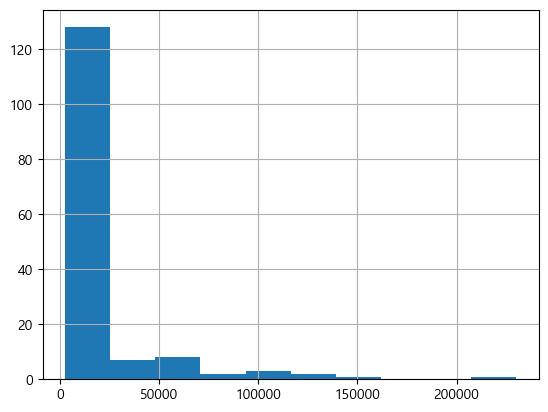

In [10]:
# 2018년 투수 연봉 분포 히스토그램
pich["연봉(2018)"].hist()
plt.show()

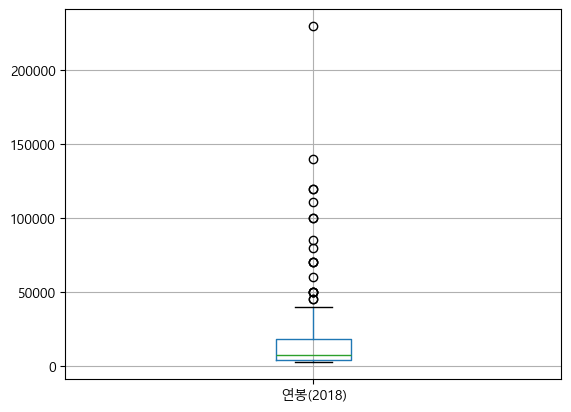

In [11]:
# 2018년 연봉의 상자 그림 출력
pich.boxplot(column = ["연봉(2018)"])
plt.show()

- 종속변수 분석
    - 수십억의 연봉을 받는 프로야구선수는 많지 않으며, 5억원 미만의 연봉이 일반적임

In [12]:
# 선수명, 팀명과 같이 그래프로 표현할 수 없는 피처 제외하고 시각화
vis_pich = pich.iloc[:, 2:]
vis_pich.head()

,승,패,세,홀드,블론,경기,선발,이닝,삼진/9,볼넷/9,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,16,7,0,0,0,30,30,190.0,8.95,2.13,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,11,11,1,0,0,30,29,185.1,7.43,1.85,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000
2,20,6,0,0,0,31,31,193.1,7.36,2.09,0.79,0.332,72.1,3.44,6.54,3.94,3.82,5.64,230000,150000
3,10,7,0,0,0,28,28,175.2,8.04,1.95,1.02,0.298,75.0,3.43,6.11,4.20,4.03,4.63,100000,100000
4,13,7,0,0,0,30,30,187.1,7.49,2.11,0.91,0.323,74.1,3.80,6.13,4.36,4.31,4.38,111000,85000


In [13]:
# 피처 각각에 대한 히스토그램을 출력
def plot_hist(df):
    fig = plt.figure(figsize = (20, 16))

    # df의 열 수 만큼의 subplot을 출력
    for i in range(len(df.columns)):
        ax = fig.add_subplot(5, 5, i + 1)
        plt.hist(df[df.columns[i]], bins = 50)
        ax.set_title(df.columns[i])

    plt.tight_layout()
    plt.show()

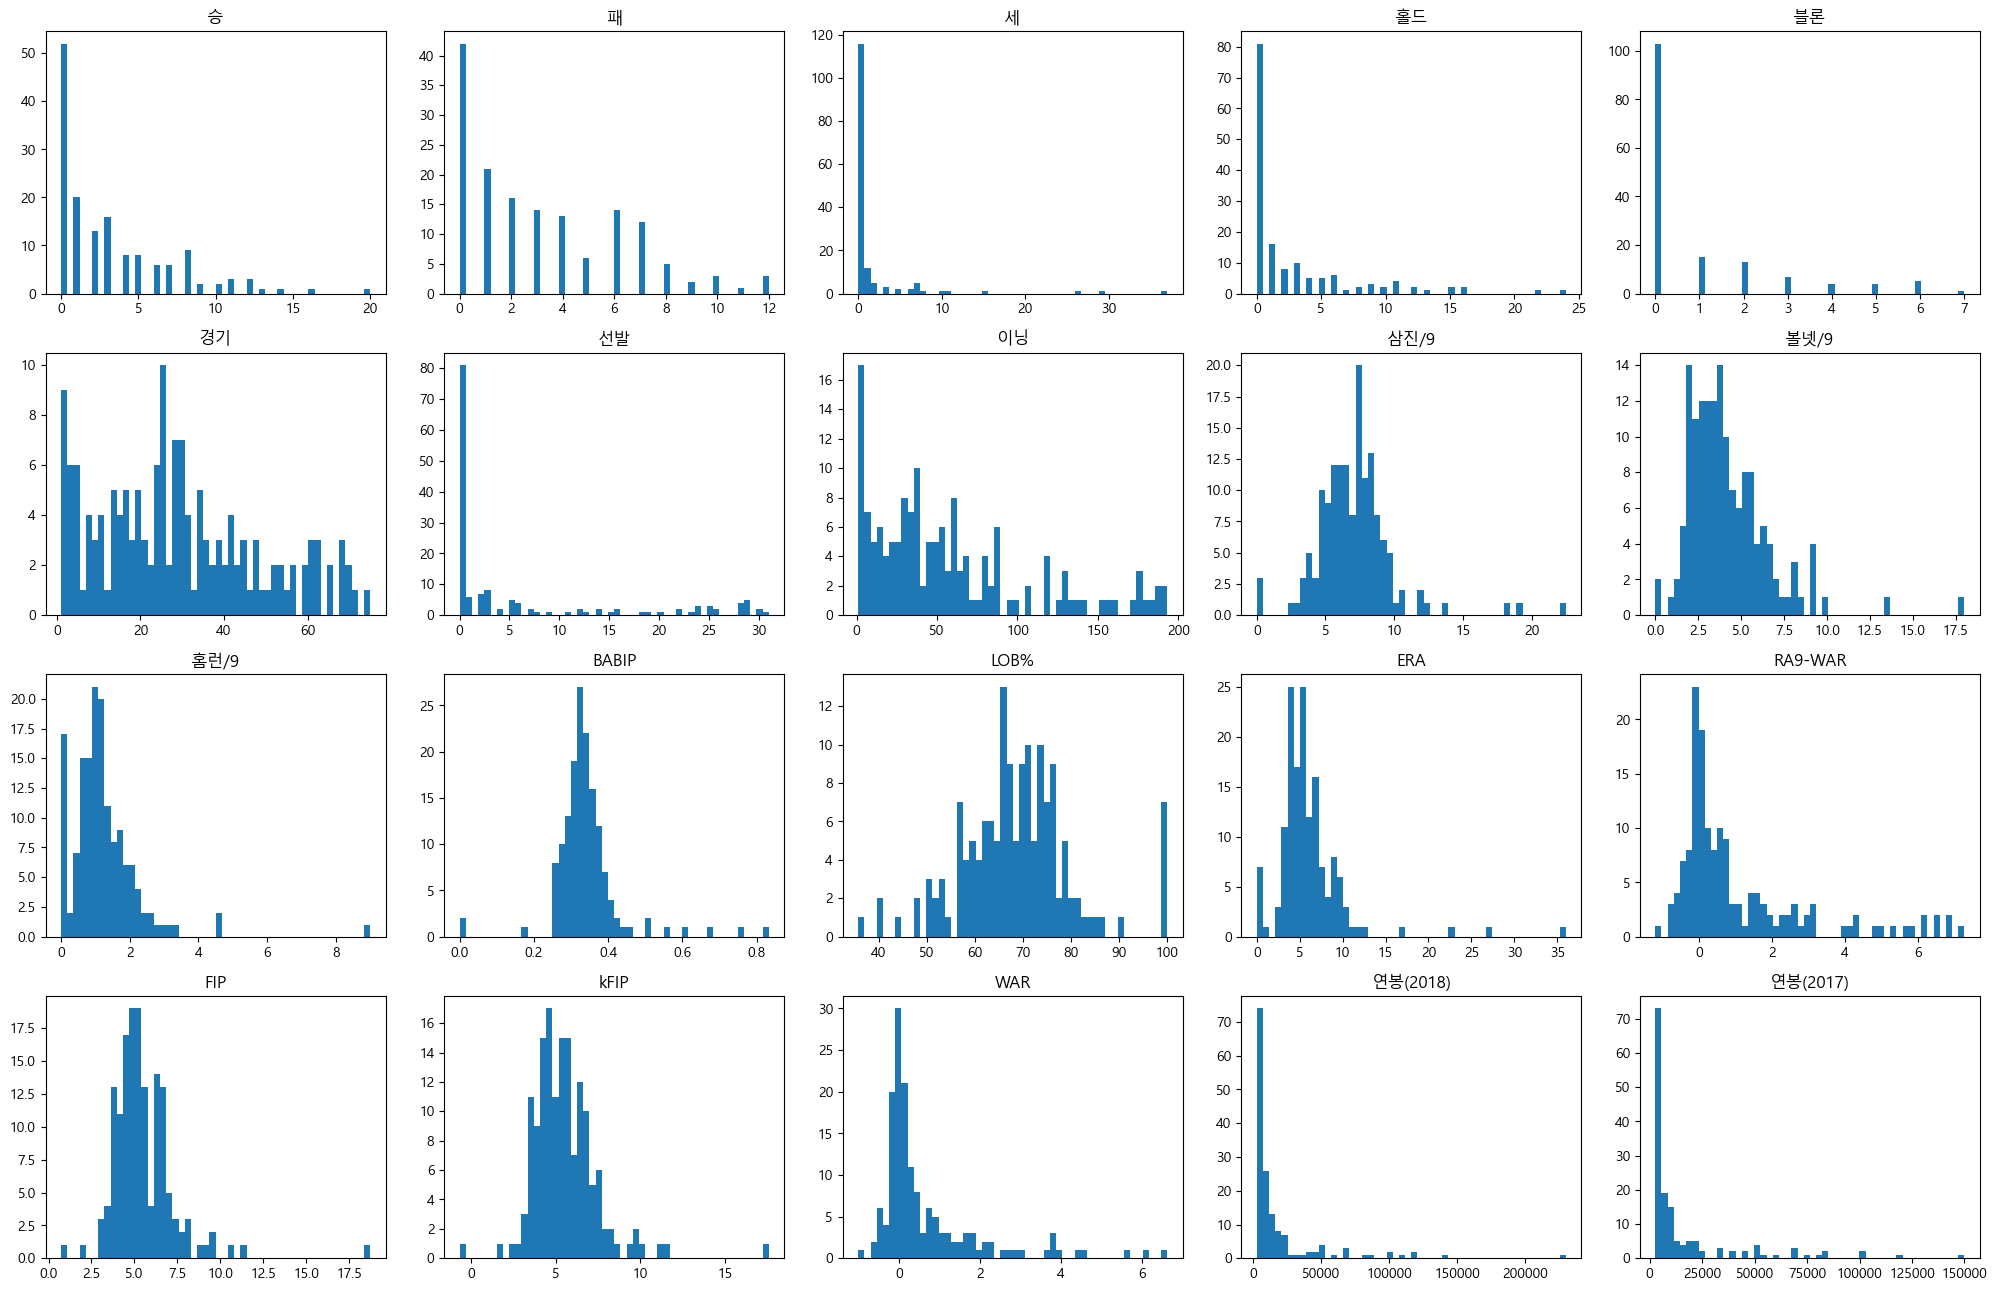

In [14]:
plot_hist(vis_pich)

- 매우 불균형한 분포를 가지고 있는 피처들이 많음

- 각 피처간의 단위가 많이 다름
    - 스케일링이 필요함
        - 선형회귀도 단위가 큰 데이터의 영향을 크게 받을 수 있음

## 데이터 전처리

In [15]:
# 재계약하여 연봉이 변화한 선수만 대상으로 필터링
# 재계약을 하지 않는다면 연봉에 변화가 없어 예측이 의미가 없기 때문
pich = pich[pich["연봉(2018)"] != pich["연봉(2017)"]]

In [16]:
pich.shape

(128, 22)

### 원핫인코딩

In [17]:
pich["팀명"].unique()

array(['SK', 'LG', 'KIA', '롯데', 'KT', '두산', '삼성', 'NC', '한화'],
      dtype=object)

In [18]:
ohe = OneHotEncoder()

In [19]:
team_arr = np.array(pich["팀명"])

In [20]:
team_arr = np.reshape(team_arr, (-1, 1))

In [21]:
team_name = ohe.fit_transform(team_arr)

In [22]:
ohe.get_feature_names_out()

array(['x0_KIA', 'x0_KT', 'x0_LG', 'x0_NC', 'x0_SK', 'x0_두산', 'x0_롯데',
       'x0_삼성', 'x0_한화'], dtype=object)

In [23]:
team_name

<128x9 sparse matrix of type '<class 'numpy.float64'>'
	with 128 stored elements in Compressed Sparse Row format>

In [24]:
ohe_team_df = pd.DataFrame(team_name.toarray(), columns = ohe.get_feature_names_out())

In [25]:
ohe_team_df.head()

,x0_KIA,x0_KT,x0_LG,x0_NC,x0_SK,x0_두산,x0_롯데,x0_삼성,x0_한화
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:
ohe_team_df.shape

(128, 9)

In [27]:
pich.head()

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000
2,양현종,KIA,20,6,0,0,0,31,31,193.1,...,0.79,0.332,72.1,3.44,6.54,3.94,3.82,5.64,230000,150000
4,레일리,롯데,13,7,0,0,0,30,30,187.1,...,0.91,0.323,74.1,3.80,6.13,4.36,4.31,4.38,111000,85000
5,피어밴드,KT,8,10,0,0,0,26,26,160.0,...,1.12,0.289,76.1,3.04,6.52,4.42,4.32,3.94,85000,35000


In [28]:
pich = pd.concat([pich.reset_index(drop = True), ohe_team_df], axis = 1)

In [29]:
pich.shape

(128, 31)

In [30]:
pich.head()

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,연봉(2017),x0_KIA,x0_KT,x0_LG,x0_NC,x0_SK,x0_두산,x0_롯데,x0_삼성,x0_한화
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,85000,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,소사,LG,11,11,1,0,0,30,29,185.1,...,50000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,양현종,KIA,20,6,0,0,0,31,31,193.1,...,150000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,레일리,롯데,13,7,0,0,0,30,30,187.1,...,85000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,피어밴드,KT,8,10,0,0,0,26,26,160.0,...,35000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [31]:
pich = pich.drop("팀명", axis = 1)

In [32]:
pich.head()

,선수명,승,패,세,홀드,블론,경기,선발,이닝,삼진/9,...,연봉(2017),x0_KIA,x0_KT,x0_LG,x0_NC,x0_SK,x0_두산,x0_롯데,x0_삼성,x0_한화
0,켈리,16,7,0,0,0,30,30,190.0,8.95,...,85000,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,소사,11,11,1,0,0,30,29,185.1,7.43,...,50000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,양현종,20,6,0,0,0,31,31,193.1,7.36,...,150000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,레일리,13,7,0,0,0,30,30,187.1,7.49,...,85000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,피어밴드,8,10,0,0,0,26,26,160.0,7.42,...,35000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [33]:
pich.shape

(128, 30)

## 데이터 분할

In [34]:
x = pich.drop(["선수명", "연봉(2018)"], axis = 1)
y = pich["연봉(2018)"]

In [35]:
x.head()

,승,패,세,홀드,블론,경기,선발,이닝,삼진/9,볼넷/9,...,연봉(2017),x0_KIA,x0_KT,x0_LG,x0_NC,x0_SK,x0_두산,x0_롯데,x0_삼성,x0_한화
0,16,7,0,0,0,30,30,190.0,8.95,2.13,...,85000,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,11,11,1,0,0,30,29,185.1,7.43,1.85,...,50000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,20,6,0,0,0,31,31,193.1,7.36,2.09,...,150000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,13,7,0,0,0,30,30,187.1,7.49,2.11,...,85000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,8,10,0,0,0,26,26,160.0,7.42,1.74,...,35000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [36]:
x.shape

(128, 28)

In [37]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 25)

In [38]:
x_train.shape, x_test.shape

((102, 28), (26, 28))

### 스케일링

In [39]:
x_train.columns

Index(['승', '패', '세', '홀드', '블론', '경기', '선발', '이닝', '삼진/9', '볼넷/9', '홈런/9',
       'BABIP', 'LOB%', 'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR', '연봉(2017)',
       'x0_KIA', 'x0_KT', 'x0_LG', 'x0_NC', 'x0_SK', 'x0_두산', 'x0_롯데', 'x0_삼성',
       'x0_한화'],
      dtype='object')

In [40]:
scale_col = x_train.columns[:-9].tolist()

In [41]:
scale_col

['승',
 '패',
 '세',
 '홀드',
 '블론',
 '경기',
 '선발',
 '이닝',
 '삼진/9',
 '볼넷/9',
 '홈런/9',
 'BABIP',
 'LOB%',
 'ERA',
 'RA9-WAR',
 'FIP',
 'kFIP',
 'WAR',
 '연봉(2017)']

In [42]:
x_train[scale_col].head()

,승,패,세,홀드,블론,경기,선발,이닝,삼진/9,볼넷/9,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2017)
64,1,2,0,0,0,10,7,31.1,7.47,5.46,2.01,0.376,56.9,8.04,-0.67,6.99,6.97,0.12,2700
27,4,7,6,16,2,66,0,75.1,12.31,5.26,1.43,0.265,78.5,4.18,1.82,4.82,4.26,0.93,21000
95,2,2,0,3,1,21,6,41.1,7.40,4.14,1.74,0.379,68.2,6.53,0.07,6.13,6.09,-0.06,2800
82,0,0,0,0,0,7,0,8.2,7.27,3.12,1.04,0.346,66.2,6.23,0.07,5.35,5.46,-0.00,3300
7,8,6,0,0,0,23,19,118.1,5.55,1.37,0.68,0.331,72.3,3.65,4.25,4.07,4.19,2.79,3100


In [43]:
x_train[scale_col].shape

(102, 19)

In [44]:
pich_ss = StandardScaler()

In [45]:
scaled_train = pich_ss.fit_transform(x_train[scale_col])
scaled_test = pich_ss.transform(x_test[scale_col])

In [46]:
scaled_test

array([[-8.15155601e-01, -9.90042253e-01,  3.33619898e-02,
        -1.52110180e-01, -5.04497842e-01,  7.79885207e-01,
        -6.39827380e-01, -1.84918927e-01, -4.38035814e-01,
         5.85508690e-01, -4.42443350e-01, -3.35363722e-01,
         6.08132432e-01, -4.18396572e-01, -1.28793008e-01,
        -1.38438820e-01, -4.66625407e-02, -4.24780835e-01,
        -9.88829925e-02],
       [ 8.42237183e-01,  2.89396966e+00, -2.75994643e-01,
        -5.71440945e-01, -5.04497842e-01,  4.86468120e-02,
         2.56255738e+00,  2.18789713e+00, -8.08350935e-01,
        -4.71551416e-01,  1.81462941e-01, -5.82675325e-01,
         2.47226746e-01, -2.45276197e-01,  1.34820615e+00,
         1.79804400e-01,  2.69326117e-01,  9.65410989e-02,
        -3.89577616e-01],
       [ 1.35407907e-02, -6.66374594e-01, -2.75994643e-01,
         4.76885969e-01,  1.47468600e+00,  5.70959951e-01,
        -4.18973259e-01, -1.84918927e-01,  1.59002851e-01,
        -7.72994412e-01, -8.11115250e-01,  3.02439886e-01,
    

In [47]:
scaled_train = pd.DataFrame(scaled_train, columns = scale_col)
scaled_test = pd.DataFrame(scaled_test, columns = scale_col)

In [48]:
scaled_train.head()

,승,패,세,홀드,블론,경기,선발,이닝,삼진/9,볼넷/9,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2017)
0,-0.538923,-0.342707,-0.275995,-0.571441,-0.504498,-0.943748,0.133162,-0.486914,0.132552,0.464931,0.710838,0.328473,-0.974300,0.372035,-0.903317,0.708499,0.659375,-0.358581,-0.477824
1,0.289773,1.275631,1.580145,2.783205,0.814958,1.981205,-0.639827,0.462213,1.961455,0.384547,0.162557,-1.116348,1.024562,-0.507235,0.591694,-0.405352,-0.678640,0.311690,0.472124
2,-0.262691,-0.342707,-0.275995,0.057555,0.155230,-0.369204,0.022735,-0.271203,0.106101,-0.065608,0.455604,0.367522,0.071401,0.028072,-0.459016,0.267065,0.224890,-0.507530,-0.472633
3,-0.815156,-0.990042,-0.275995,-0.571441,-0.504498,-1.100442,-0.639827,-0.980891,0.056977,-0.475571,-0.206115,-0.062019,-0.113679,-0.040265,-0.459016,-0.133306,-0.086161,-0.457881,-0.446678
4,1.394701,0.951964,-0.275995,-0.571441,-0.504498,-0.264741,1.458287,1.389768,-0.592964,-1.178938,-0.546428,-0.257265,0.450815,-0.627963,2.050681,-0.790324,-0.713201,1.850831,-0.457060


In [49]:
x_train.iloc[:, -9:].head()

,x0_KIA,x0_KT,x0_LG,x0_NC,x0_SK,x0_두산,x0_롯데,x0_삼성,x0_한화
64,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
27,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
95,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
82,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
7,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [50]:
scaled_train = pd.concat([scaled_train, x_train.iloc[:, -9:].reset_index(drop = True)], axis = 1)
scaled_test = pd.concat([scaled_test, x_test.iloc[:, -9:].reset_index(drop = True)], axis = 1)

In [51]:
scaled_train.shape, scaled_test.shape

((102, 28), (26, 28))

## 모델 훈련

In [52]:
lr = LinearRegression()

In [53]:
lr.fit(scaled_train, y_train)

LinearRegression()

## 모델 평가

In [54]:
lr.score(scaled_test, y_test)

0.9099143110473389

In [55]:
pred = lr.predict(scaled_test)

In [56]:
mae = mean_absolute_error(y_test, pred)

In [57]:
mae

6187.559946438224

# 모델 최적화

In [58]:
# statsmodels 라이브러리로 회귀 분석
X = sm.add_constant(scaled_train) # 상수항 추가

In [59]:
model = sm.OLS(y_train.reset_index(drop = True), X)

In [60]:
model = model.fit()

In [61]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.883
Method:                 Least Squares   F-statistic:                     29.30
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           1.89e-29
Time:                        09:06:26   Log-Likelihood:                -1064.4
No. Observations:                 102   AIC:                             2185.
Df Residuals:                      74   BIC:                             2258.
Df Model:                          27                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.326e+04    897.373     14.773      0.000    1.15e+04     1.5e+04
승           1904.0537   2805.003      0.679      0.499   -3685.036    7493.144
패          -1280.1918   2348.325     -0.545      0.587   -5959.332    3398.949
세           -417.6145   1433.576     -0.291      0.772   -3274.077    2438.848
홀드          -889.0102   1868.991     -0.476      0.636   -4613.056    2835.036
블론            43.2939   1709.458      0.025      0.980   -3362.876    3449.463
경기         -4461.1202   3797.288     -1.175      0.244    -1.2e+04    3105.142
선발         -8735.5418   5660.476     -1.543      0.127      -2e+04    2543.202
이닝          7790.3072   7933.957      0.982      0.329   -8018.448    2.36e+04
삼진/9        1063.1920   1.01e+04      0.106      0.916    -1.9e+04    2.11e+04
볼넷/9        8614.3015   1.05e+04      0.819      0.415   -1.23e+04    2.96e+04
홈런/9        1.411e+04   2.74e+04      0.515      0.608   -4.05e+04    6.87e+04
BABIP      -3647.0160   2262.862     -1.612      0.111   -8155.867     861.835
LOB%         659.7230   2143.482      0.308      0.759   -3611.258    4930.704
ERA         1398.7825   3543.307      0.395      0.694   -5661.411    8458.976
RA9-WAR      557.3366   3741.940      0.149      0.882   -6898.642    8013.315
FIP         -5.72e+04   1.55e+05     -0.368      0.714   -3.67e+05    2.52e+05
kFIP        4.154e+04   1.28e+05      0.325      0.746   -2.14e+05    2.97e+05
WAR         1.018e+04   3700.152      2.752      0.007    2809.667    1.76e+04
연봉(2017)    1.896e+04   1498.286     12.652      0.000     1.6e+04    2.19e+04
x0_KIA      3304.2268   3089.043      1.070      0.288   -2850.826    9459.279
x0_KT       3365.9141   2797.463      1.203      0.233   -2208.152    8939.980
x0_LG       1943.5627   2787.555      0.697      0.488   -3610.762    7497.887
x0_NC      -1716.9443   3092.526     -0.555      0.580   -7878.936    4445.048
x0_SK       1874.2452   3078.735      0.609      0.545   -4260.268    8008.759
x0_두산       2626.5279   4144.213      0.634      0.528   -5630.998    1.09e+04
x0_롯데       -397.6572   3394.010     -0.117      0.907   -7160.370    6365.056
x0_삼성      -2828.1274   2942.665     -0.961      0.340   -8691.515    3035.260
x0_한화       5085.4205   2936.506      1.732      0.087    -765.696    1.09e+04
==============================================================================
Omnibus:                       45.519   Durbin-Watson:                   1.983
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              309.936
Skew:                          -1.189   Prob(JB):                     4.99e-68
Kurtosis:                      11.202   Cond. No.                     2.59e+16
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is co

- F-statistic : 회귀식의 유의성 검정에 사용되는 값으로, Prob(F-statistic) 과 함께 해석해야함
- prob(F-statistic) : F통계량에 대한 p-value. 일반적으로 0.05 이하면 회귀 분석이 유의미한 의미를 가짐
- P>|t| : 각 피처가 얼마나 유의미한지를 나타내는 p-value

In [62]:
# 계수 시각화
# 회귀 계수를 시리즈로 변환
coefs = model.params.tolist()
coefs_se = pd.Series(coefs)

# 변수명을 리스트로 반환
x_labels = model.params.index.tolist()

C:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


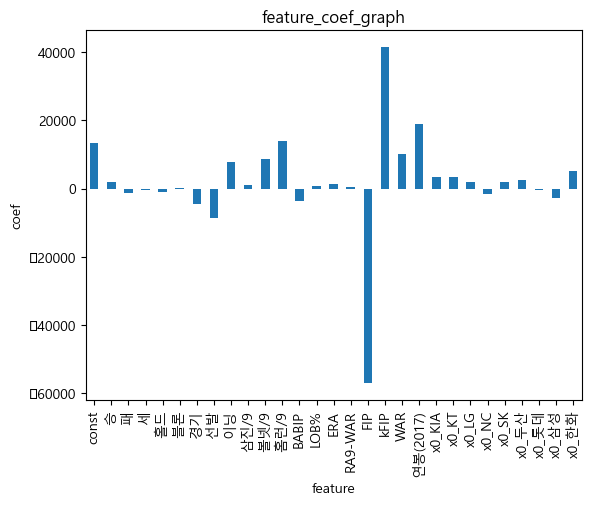

In [63]:
ax = coefs_se.plot(kind = "bar")
ax.set_title("feature_coef_graph")
ax.set_xlabel("feature")
ax.set_ylabel("coef")
ax.set_xticklabels(x_labels)
plt.show()

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.draw()
C:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


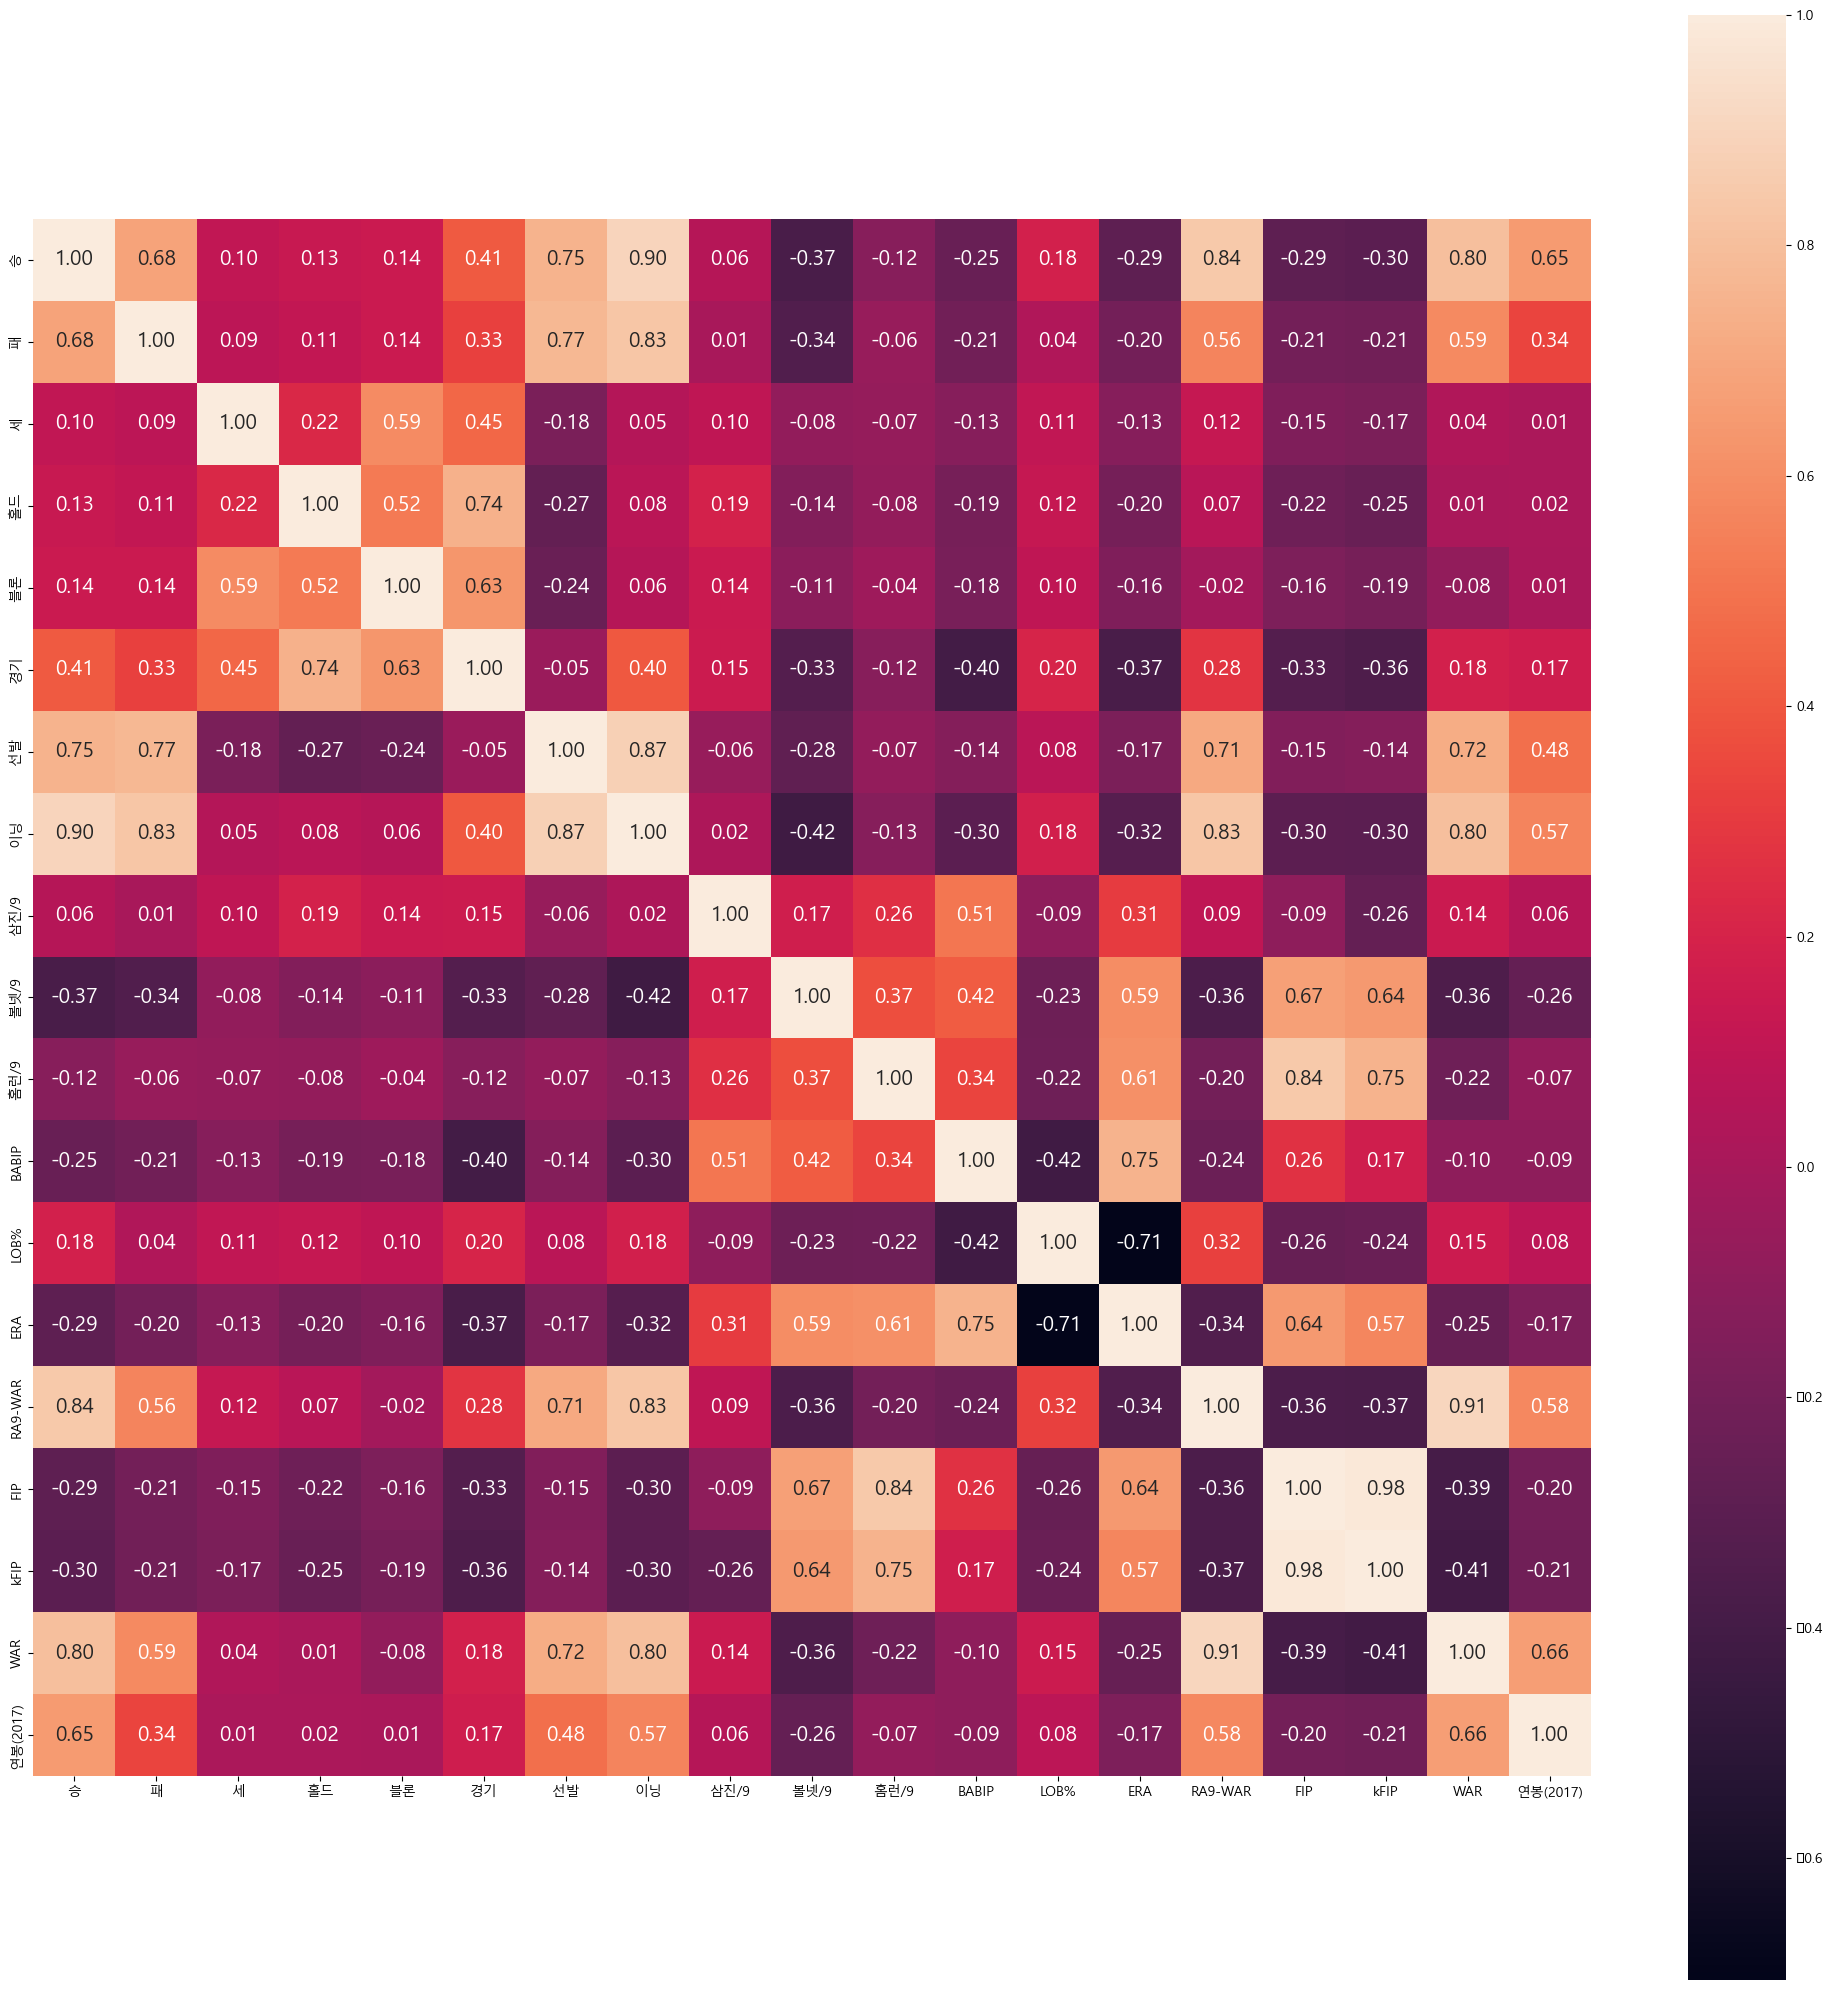

In [64]:
# 피처들의 상관관계 시각화
corr = pich[scale_col].corr()
fig = plt.figure(figsize = (20, 20))
hm = sns.heatmap(corr.values, cbar = True, annot = True, square = True, fmt = ".2f",
                 annot_kws = {"size" : 15}, yticklabels = scale_col, xticklabels = scale_col)
plt.tight_layout()
plt.show()

- 몇몇 피처 쌍에서 높은 연관성을 발견할 수 있음

- 회귀 분석은 피처 간의 독립성을 전제로 하는 분석이기 때문에 올바른 회귀 분석을 하기 위해서는 연관성이 높은 쌍을 제거해야함
    - 다중공선성
        - 변수 간 상관관계가 높아 분석에 부정적인 영향을 미치는 것
        - 모델 성능을 위해 어떤 피처를 제거하는 것이 옳은 판단일지에 대한 기준을 제시할 수 있음
        - 다중공선성은 분산팽창요인(Variance Inflation Factor(VIF)) 이라는 계수로 평가
            - 일반적으로 VIF 가 15를 넘으면 다중 공선성의 문제가 발생했다고 판단함

In [65]:
# 피처마다 VIF 계수를 출력
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif["feature"] = X.columns
vif.round(1)

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1783: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,VIF_Factor,feature
0,0.0,const
1,8.6,승
2,6.0,패
3,2.2,세
4,3.8,홀드
5,3.2,블론
6,15.7,경기
7,35.0,선발
8,68.7,이닝
9,110.8,삼진/9


#### 변수제거 1

- 제거된 변수 : 블론

- 무의미한 변수가 다중공선성보다 더 심각한 문제를 유발하기 때문

- 최종적으로는 P값이 높은 변수, VIF가 높은 변수 모두 제거되어야 함

In [70]:
new_X = X.drop("블론", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.885
Method:                 Least Squares   F-statistic:                     30.84
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           3.36e-30
Time:                        09:31:12   Log-Likelihood:                -1064.4
No. Observations:                 102   AIC:                             2183.
Df Residuals:                      75   BIC:                             2254.
Df Model:                          26                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.326e+04    891.148     14.877      0.000    1.15e+04     1.5e+04
승           1916.4312   2743.635      0.699      0.487   -3549.169    7382.032
패          -1268.4857   2286.997     -0.555      0.581   -5824.418    3287.446
세           -401.5305   1276.639     -0.315      0.754   -2944.726    2141.665
홀드          -883.3737   1843.288     -0.479      0.633   -4555.391    2788.644
경기         -4460.7243   3771.872     -1.183      0.241    -1.2e+04    3053.231
선발         -8768.1519   5475.235     -1.601      0.113   -1.97e+04    2139.076
이닝          7810.9496   7839.224      0.996      0.322   -7805.586    2.34e+04
삼진/9        1038.2001   9961.275      0.104      0.917   -1.88e+04    2.09e+04
볼넷/9        8597.1190   1.04e+04      0.825      0.412   -1.22e+04    2.94e+04
홈런/9        1.404e+04   2.71e+04      0.518      0.606   -3.99e+04     6.8e+04
BABIP      -3655.8618   2220.799     -1.646      0.104   -8079.920     768.196
LOB%         665.5433   2116.881      0.314      0.754   -3551.499    4882.586
ERA         1404.7656   3511.790      0.400      0.690   -5591.078    8400.609
RA9-WAR      538.1653   3640.077      0.148      0.883   -6713.239    7789.570
FIP        -5.679e+04   1.53e+05     -0.370      0.712   -3.62e+05    2.49e+05
kFIP        4.119e+04   1.26e+05      0.326      0.745   -2.11e+05    2.93e+05
WAR         1.018e+04   3675.225      2.770      0.007    2859.998    1.75e+04
연봉(2017)    1.896e+04   1482.555     12.788      0.000     1.6e+04    2.19e+04
x0_KIA      3304.3268   3068.391      1.077      0.285   -2808.222    9416.875
x0_KT       3364.2081   2777.957      1.211      0.230   -2169.765    8898.182
x0_LG       1944.2842   2768.776      0.702      0.485   -3571.401    7459.969
x0_NC      -1737.3350   2965.923     -0.586      0.560   -7645.756    4171.086
x0_SK       1892.2315   2975.678      0.636      0.527   -4035.624    7820.087
x0_두산       2620.0868   4108.751      0.638      0.526   -5564.966    1.08e+04
x0_롯데       -376.7266   3269.848     -0.115      0.909   -6890.598    6137.145
x0_삼성      -2844.7157   2849.666     -0.998      0.321   -8521.542    2832.110
x0_한화       5091.3207   2907.683      1.751      0.084    -701.081    1.09e+04
==============================================================================
Omnibus:                       45.427   Durbin-Watson:                   1.985
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              308.535
Skew:                          -1.187   Prob(JB):                     1.01e-67
Kurtosis:                      11.183   Cond. No.                     3.11e+16
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 7.07e-31. This might indicate

In [71]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1783: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,VIF_Factor,feature
0,0.0,const
1,8.3,승
2,5.8,패
3,1.8,세
4,3.8,홀드
5,15.7,경기
6,33.2,선발
7,68.0,이닝
8,109.8,삼진/9
9,120.1,볼넷/9


#### 변수제거 2

- 제거된 변수 : 블론, 삼진/9

In [72]:
new_X = new_X.drop("삼진/9", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.886
Method:                 Least Squares   F-statistic:                     32.50
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           5.84e-31
Time:                        09:31:14   Log-Likelihood:                -1064.4
No. Observations:                 102   AIC:                             2181.
Df Residuals:                      76   BIC:                             2249.
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.325e+04    884.002     14.992      0.000    1.15e+04     1.5e+04
승           1959.8709   2694.087      0.727      0.469   -3405.868    7325.610
패          -1232.9152   2246.624     -0.549      0.585   -5707.455    3241.625
세           -407.5258   1267.016     -0.322      0.749   -2931.007    2115.955
홀드          -896.7915   1826.782     -0.491      0.625   -4535.142    2741.559
경기         -4361.2033   3625.180     -1.203      0.233   -1.16e+04    2858.968
선발         -8693.5605   5392.819     -1.612      0.111   -1.94e+04    2047.169
이닝          7602.7932   7531.049      1.010      0.316   -7396.590    2.26e+04
볼넷/9        7758.2800   6576.123      1.180      0.242   -5339.203    2.09e+04
홈런/9         1.16e+04   1.36e+04      0.851      0.398   -1.56e+04    3.88e+04
BABIP      -3690.3851   2181.620     -1.692      0.095   -8035.458     654.687
LOB%         670.5310   2102.523      0.319      0.751   -3517.006    4858.068
ERA         1451.9145   3459.794      0.420      0.676   -5438.861    8342.691
RA9-WAR      535.7164   3616.236      0.148      0.883   -6666.642    7738.075
FIP         -4.18e+04   5.32e+04     -0.786      0.434   -1.48e+05    6.41e+04
kFIP        2.863e+04   3.77e+04      0.758      0.451   -4.65e+04    1.04e+05
WAR         1.023e+04   3622.875      2.823      0.006    3013.488    1.74e+04
연봉(2017)    1.895e+04   1467.336     12.912      0.000     1.6e+04    2.19e+04
x0_KIA      3274.7736   3035.314      1.079      0.284   -2770.578    9320.125
x0_KT       3338.9035   2749.259      1.214      0.228   -2136.721    8814.528
x0_LG       1948.9221   2750.344      0.709      0.481   -3528.863    7426.707
x0_NC      -1755.4511   2941.494     -0.597      0.552   -7613.944    4103.042
x0_SK       1966.5675   2870.076      0.685      0.495   -3749.684    7682.819
x0_두산       2535.6994   4001.884      0.634      0.528   -5434.744    1.05e+04
x0_롯데       -375.0577   3248.461     -0.115      0.908   -6844.928    6094.813
x0_삼성      -2809.9172   2811.562     -0.999      0.321   -8409.628    2789.794
x0_한화       5128.1545   2867.282      1.789      0.078    -582.533    1.08e+04
==============================================================================
Omnibus:                       45.904   Durbin-Watson:                   1.982
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              314.272
Skew:                          -1.201   Prob(JB):                     5.71e-69
Kurtosis:                      11.257   Cond. No.                     3.73e+16
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 4.94e-31. This might indicate that there are
strong multicollinearity problems or that the design matrix is 

In [73]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1783: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,VIF_Factor,feature
0,0.0,const
1,8.1,승
2,5.7,패
3,1.8,세
4,3.7,홀드
5,14.7,경기
6,32.6,선발
7,63.6,이닝
8,48.5,볼넷/9
9,208.5,홈런/9


#### 변수제거 3

- 제거된 변수 : 블론, 삼진/9, x0_롯데

In [74]:
new_X = new_X.drop("x0_롯데", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.886
Method:                 Least Squares   F-statistic:                     32.50
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           5.84e-31
Time:                        09:34:39   Log-Likelihood:                -1064.4
No. Observations:                 102   AIC:                             2181.
Df Residuals:                      76   BIC:                             2249.
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.288e+04   3451.785      3.731      0.000    6002.711    1.98e+04
승           1959.8709   2694.087      0.727      0.469   -3405.868    7325.610
패          -1232.9152   2246.624     -0.549      0.585   -5707.455    3241.625
세           -407.5258   1267.016     -0.322      0.749   -2931.007    2115.955
홀드          -896.7915   1826.782     -0.491      0.625   -4535.142    2741.559
경기         -4361.2033   3625.180     -1.203      0.233   -1.16e+04    2858.968
선발         -8693.5605   5392.819     -1.612      0.111   -1.94e+04    2047.169
이닝          7602.7932   7531.049      1.010      0.316   -7396.590    2.26e+04
볼넷/9        7758.2800   6576.123      1.180      0.242   -5339.203    2.09e+04
홈런/9         1.16e+04   1.36e+04      0.851      0.398   -1.56e+04    3.88e+04
BABIP      -3690.3851   2181.620     -1.692      0.095   -8035.458     654.687
LOB%         670.5310   2102.523      0.319      0.751   -3517.006    4858.068
ERA         1451.9145   3459.794      0.420      0.676   -5438.861    8342.691
RA9-WAR      535.7164   3616.236      0.148      0.883   -6666.642    7738.075
FIP         -4.18e+04   5.32e+04     -0.786      0.434   -1.48e+05    6.41e+04
kFIP        2.863e+04   3.77e+04      0.758      0.451   -4.65e+04    1.04e+05
WAR         1.023e+04   3622.875      2.823      0.006    3013.488    1.74e+04
연봉(2017)    1.895e+04   1467.336     12.912      0.000     1.6e+04    2.19e+04
x0_KIA      3649.8313   4614.857      0.791      0.431   -5541.452    1.28e+04
x0_KT       3713.9611   4597.423      0.808      0.422   -5442.599    1.29e+04
x0_LG       2323.9798   4477.750      0.519      0.605   -6594.232    1.12e+04
x0_NC      -1380.3934   4621.157     -0.299      0.766   -1.06e+04    7823.438
x0_SK       2341.6252   4461.805      0.525      0.601   -6544.830    1.12e+04
x0_두산       2910.7570   5558.023      0.524      0.602   -8159.005     1.4e+04
x0_삼성      -2434.8595   4697.635     -0.518      0.606   -1.18e+04    6921.290
x0_한화       5503.2122   4648.165      1.184      0.240   -3754.410    1.48e+04
==============================================================================
Omnibus:                       45.904   Durbin-Watson:                   1.982
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              314.272
Skew:                          -1.201   Prob(JB):                     5.71e-69
Kurtosis:                      11.257   Cond. No.                         183.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [75]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,13.4,const
1,8.1,승
2,5.7,패
3,1.8,세
4,3.7,홀드
5,14.7,경기
6,32.6,선발
7,63.6,이닝
8,48.5,볼넷/9
9,208.5,홈런/9


#### 변수제거 4

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR

In [76]:
new_X = new_X.drop("RA9-WAR", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.888
Method:                 Least Squares   F-statistic:                     34.29
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           9.94e-32
Time:                        09:36:51   Log-Likelihood:                -1064.4
No. Observations:                 102   AIC:                             2179.
Df Residuals:                      77   BIC:                             2244.
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.295e+04   3390.407      3.821      0.000    6203.646    1.97e+04
승           2042.3108   2619.191      0.780      0.438   -3173.165    7257.787
패          -1359.3296   2065.014     -0.658      0.512   -5471.297    2752.638
세           -350.5757   1199.596     -0.292      0.771   -2739.276    2038.124
홀드          -846.3062   1783.278     -0.475      0.636   -4397.266    2704.654
경기         -4429.8301   3572.552     -1.240      0.219   -1.15e+04    2684.029
선발         -8707.8738   5357.600     -1.625      0.108   -1.94e+04    1960.470
이닝          7800.2108   7364.981      1.059      0.293   -6865.340    2.25e+04
볼넷/9        7745.4078   6533.654      1.185      0.239   -5264.759    2.08e+04
홈런/9        1.157e+04   1.35e+04      0.854      0.396   -1.54e+04    3.85e+04
BABIP      -3800.8600   2037.143     -1.866      0.066   -7857.330     255.610
LOB%         813.5848   1855.750      0.438      0.662   -2881.686    4508.856
ERA         1619.5812   3248.605      0.499      0.620   -4849.217    8088.380
FIP        -4.177e+04   5.28e+04     -0.791      0.432   -1.47e+05    6.34e+04
kFIP        2.859e+04   3.75e+04      0.762      0.448   -4.61e+04    1.03e+05
WAR         1.062e+04   2472.752      4.294      0.000    5695.230    1.55e+04
연봉(2017)    1.889e+04   1402.457     13.467      0.000    1.61e+04    2.17e+04
x0_KIA      3590.3884   4568.088      0.786      0.434   -5505.837    1.27e+04
x0_KT       3601.7482   4505.702      0.799      0.427   -5370.251    1.26e+04
x0_LG       2219.4382   4393.620      0.505      0.615   -6529.378     1.1e+04
x0_NC      -1501.4136   4519.398     -0.332      0.741   -1.05e+04    7497.857
x0_SK       2276.2325   4411.628      0.516      0.607   -6508.441    1.11e+04
x0_두산       2829.3777   5495.571      0.515      0.608   -8113.702    1.38e+04
x0_삼성      -2512.1932   4638.795     -0.542      0.590   -1.17e+04    6724.827
x0_한화       5453.0336   4606.271      1.184      0.240   -3719.223    1.46e+04
==============================================================================
Omnibus:                       45.184   Durbin-Watson:                   1.987
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              300.912
Skew:                          -1.187   Prob(JB):                     4.55e-66
Kurtosis:                      11.073   Cond. No.                         175.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [77]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,13.1,const
1,7.8,승
2,4.8,패
3,1.6,세
4,3.6,홀드
5,14.5,경기
6,32.6,선발
7,61.6,이닝
8,48.5,볼넷/9
9,208.4,홈런/9


#### 변수제거 5

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세

In [78]:
new_X = new_X.drop("세", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.889
Method:                 Least Squares   F-statistic:                     36.20
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           1.69e-32
Time:                        09:40:41   Log-Likelihood:                -1064.4
No. Observations:                 102   AIC:                             2177.
Df Residuals:                      78   BIC:                             2240.
Df Model:                          23                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.301e+04   3365.119      3.866      0.000    6311.187    1.97e+04
승           2071.5300   2601.892      0.796      0.428   -3108.440    7251.500
패          -1468.4368   2019.042     -0.727      0.469   -5488.041    2551.167
홀드          -640.0042   1627.977     -0.393      0.695   -3881.058    2601.049
경기         -4802.4645   3317.637     -1.448      0.152   -1.14e+04    1802.443
선발         -8767.9858   5322.170     -1.647      0.103   -1.94e+04    1827.641
이닝          8157.4488   7220.124      1.130      0.262   -6216.715    2.25e+04
볼넷/9        7587.9212   6473.105      1.172      0.245   -5299.041    2.05e+04
홈런/9        1.133e+04   1.34e+04      0.843      0.402   -1.54e+04    3.81e+04
BABIP      -3726.0281   2009.103     -1.855      0.067   -7725.844     273.788
LOB%         677.9639   1786.224      0.380      0.705   -2878.135    4234.063
ERA         1443.7914   3173.659      0.455      0.650   -4874.478    7762.060
FIP        -4.068e+04   5.24e+04     -0.777      0.440   -1.45e+05    6.36e+04
kFIP        2.785e+04   3.72e+04      0.749      0.456   -4.62e+04    1.02e+05
WAR         1.049e+04   2418.769      4.337      0.000    5674.775    1.53e+04
연봉(2017)    1.885e+04   1388.575     13.575      0.000    1.61e+04    2.16e+04
x0_KIA      3523.6385   4535.547      0.777      0.440   -5505.942    1.26e+04
x0_KT       3582.2306   4478.716      0.800      0.426   -5334.208    1.25e+04
x0_LG       2207.2399   4367.589      0.505      0.615   -6487.961    1.09e+04
x0_NC      -1670.3817   4455.906     -0.375      0.709   -1.05e+04    7200.645
x0_SK       2087.6157   4338.501      0.481      0.632   -6549.676    1.07e+04
x0_두산       2827.8607   5463.254      0.518      0.606   -8048.643    1.37e+04
x0_삼성      -2485.1274   4610.599     -0.539      0.591   -1.17e+04    6693.871
x0_한화       5400.9151   4575.752      1.180      0.241   -3708.708    1.45e+04
==============================================================================
Omnibus:                       44.041   Durbin-Watson:                   1.986
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              289.221
Skew:                          -1.151   Prob(JB):                     1.57e-63
Kurtosis:                      10.922   Cond. No.                         174.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [79]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,13.0,const
1,7.8,승
2,4.7,패
3,3.0,홀드
4,12.6,경기
5,32.5,선발
6,59.9,이닝
7,48.1,볼넷/9
8,207.6,홈런/9
9,4.6,BABIP


#### 변수제거 6

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC

In [80]:
new_X = new_X.drop("x0_NC", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.890
Method:                 Least Squares   F-statistic:                     38.25
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           2.89e-33
Time:                        09:41:50   Log-Likelihood:                -1064.5
No. Observations:                 102   AIC:                             2175.
Df Residuals:                      79   BIC:                             2235.
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.207e+04   2222.906      5.429      0.000    7643.010    1.65e+04
승           2259.2294   2539.333      0.890      0.376   -2795.187    7313.646
패          -1545.9131   1997.481     -0.774      0.441   -5521.800    2429.974
홀드          -579.9895   1611.249     -0.360      0.720   -3787.101    2627.122
경기         -4771.2767   3298.503     -1.446      0.152   -1.13e+04    1794.230
선발         -8511.0995   5249.080     -1.621      0.109    -1.9e+04    1936.933
이닝          7945.3555   7158.661      1.110      0.270   -6303.603    2.22e+04
볼넷/9        7936.5096   6371.023      1.246      0.217   -4744.695    2.06e+04
홈런/9        1.209e+04   1.32e+04      0.915      0.363   -1.42e+04    3.84e+04
BABIP      -3630.2799   1981.931     -1.832      0.071   -7575.215     314.655
LOB%         636.1675   1773.017      0.359      0.721   -2892.934    4165.269
ERA         1405.3671   3154.701      0.445      0.657   -4873.908    7684.642
FIP        -4.392e+04   5.14e+04     -0.855      0.395   -1.46e+05    5.84e+04
kFIP         3.02e+04   3.65e+04      0.828      0.410   -4.24e+04    1.03e+05
WAR         1.043e+04   2399.498      4.345      0.000    5649.682    1.52e+04
연봉(2017)    1.882e+04   1379.109     13.648      0.000    1.61e+04    2.16e+04
x0_KIA      4376.2036   3902.719      1.121      0.266   -3391.965    1.21e+04
x0_KT       4575.0319   3592.072      1.274      0.207   -2574.809    1.17e+04
x0_LG       3172.5642   3508.464      0.904      0.369   -3810.858    1.02e+04
x0_SK       2934.6296   3683.483      0.797      0.428   -4397.160    1.03e+04
x0_두산       3681.3631   4939.130      0.745      0.458   -6149.729    1.35e+04
x0_삼성      -1427.5088   3626.736     -0.394      0.695   -8646.347    5791.329
x0_한화       6335.8146   3815.452      1.661      0.101   -1258.653    1.39e+04
==============================================================================
Omnibus:                       44.407   Durbin-Watson:                   1.985
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              288.362
Skew:                          -1.169   Prob(JB):                     2.42e-63
Kurtosis:                      10.898   Cond. No.                         171.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [81]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,5.7,const
1,7.5,승
2,4.6,패
3,3.0,홀드
4,12.6,경기
5,32.0,선발
6,59.5,이닝
7,47.1,볼넷/9
8,202.9,홈런/9
9,4.6,BABIP


#### 변수제거 7

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%

In [82]:
new_X = new_X.drop("LOB%", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.891
Method:                 Least Squares   F-statistic:                     40.51
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           4.75e-34
Time:                        09:42:53   Log-Likelihood:                -1064.6
No. Observations:                 102   AIC:                             2173.
Df Residuals:                      80   BIC:                             2231.
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.212e+04   2206.456      5.492      0.000    7726.402    1.65e+04
승           2373.6295   2505.481      0.947      0.346   -2612.438    7359.697
패          -1626.8763   1973.858     -0.824      0.412   -5554.979    2301.226
홀드          -511.7525   1591.250     -0.322      0.749   -3678.441    2654.936
경기         -4929.0374   3251.217     -1.516      0.133   -1.14e+04    1541.091
선발         -8657.4565   5204.633     -1.663      0.100    -1.9e+04    1700.093
이닝          8115.9833   7103.846      1.142      0.257   -6021.122    2.23e+04
볼넷/9        8134.2515   6312.485      1.289      0.201   -4427.994    2.07e+04
홈런/9        1.243e+04   1.31e+04      0.948      0.346   -1.37e+04    3.85e+04
BABIP      -3376.5350   1841.357     -1.834      0.070   -7040.952     287.882
ERA          500.8312   1886.184      0.266      0.791   -3252.795    4254.457
FIP        -4.399e+04   5.11e+04     -0.861      0.392   -1.46e+05    5.77e+04
kFIP        3.022e+04   3.63e+04      0.833      0.407    -4.2e+04    1.02e+05
WAR         1.044e+04   2386.117      4.375      0.000    5690.424    1.52e+04
연봉(2017)    1.877e+04   1363.125     13.768      0.000    1.61e+04    2.15e+04
x0_KIA      4152.2651   3831.455      1.084      0.282   -3472.574    1.18e+04
x0_KT       4606.3021   3571.407      1.290      0.201   -2501.025    1.17e+04
x0_LG       3186.0710   3489.106      0.913      0.364   -3757.470    1.01e+04
x0_SK       2761.2302   3631.704      0.760      0.449   -4466.092    9988.552
x0_두산       3772.4030   4905.675      0.769      0.444   -5990.201    1.35e+04
x0_삼성      -1528.2075   3596.118     -0.425      0.672   -8684.710    5628.295
x0_한화       6314.6929   3794.167      1.664      0.100   -1235.940    1.39e+04
==============================================================================
Omnibus:                       44.098   Durbin-Watson:                   1.989
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              283.861
Skew:                          -1.161   Prob(JB):                     2.29e-62
Kurtosis:                      10.836   Cond. No.                         170.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [83]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,5.7,const
1,7.4,승
2,4.6,패
3,3.0,홀드
4,12.4,경기
5,31.8,선발
6,59.3,이닝
7,46.8,볼넷/9
8,201.8,홈런/9
9,4.0,BABIP


#### 변수제거 8

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA

In [84]:
new_X = new_X.drop("ERA", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.893
Method:                 Least Squares   F-statistic:                     43.02
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           7.37e-35
Time:                        09:44:05   Log-Likelihood:                -1064.7
No. Observations:                 102   AIC:                             2171.
Df Residuals:                      81   BIC:                             2226.
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.212e+04   2193.756      5.524      0.000    7753.590    1.65e+04
승           2362.8574   2490.738      0.949      0.346   -2592.930    7318.645
패          -1583.4354   1955.747     -0.810      0.421   -5474.759    2307.888
홀드          -522.4165   1581.590     -0.330      0.742   -3669.284    2624.451
경기         -4951.7294   3231.392     -1.532      0.129   -1.14e+04    1477.728
선발         -8772.2344   5156.806     -1.701      0.093    -1.9e+04    1488.192
이닝          8249.8594   7045.158      1.171      0.245   -5767.795    2.23e+04
볼넷/9        8049.3205   6268.099      1.284      0.203   -4422.231    2.05e+04
홈런/9        1.219e+04    1.3e+04      0.937      0.351   -1.37e+04    3.81e+04
BABIP      -3085.9781   1472.414     -2.096      0.039   -6015.620    -156.336
FIP        -4.278e+04   5.06e+04     -0.845      0.400   -1.43e+05    5.79e+04
kFIP         2.95e+04    3.6e+04      0.820      0.414    -4.2e+04    1.01e+05
WAR         1.039e+04   2365.771      4.393      0.000    5684.523    1.51e+04
연봉(2017)    1.877e+04   1355.039     13.855      0.000    1.61e+04    2.15e+04
x0_KIA      4229.6609   3798.369      1.114      0.269   -3327.902    1.18e+04
x0_KT       4620.1317   3550.479      1.301      0.197   -2444.208    1.17e+04
x0_LG       3193.4980   3468.917      0.921      0.360   -3708.559    1.01e+04
x0_SK       2798.7544   3608.072      0.776      0.440   -4380.177    9977.686
x0_두산       3741.0171   4876.031      0.767      0.445   -5960.754    1.34e+04
x0_삼성      -1582.8314   3569.570     -0.443      0.659   -8685.156    5519.493
x0_한화       6253.3750   3765.341      1.661      0.101   -1238.472    1.37e+04
==============================================================================
Omnibus:                       44.568   Durbin-Watson:                   1.985
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              289.332
Skew:                          -1.175   Prob(JB):                     1.49e-63
Kurtosis:                      10.909   Cond. No.                         164.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [85]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,5.7,const
1,7.4,승
2,4.5,패
3,3.0,홀드
4,12.4,경기
5,31.6,선발
6,59.0,이닝
7,46.7,볼넷/9
8,200.8,홈런/9
9,2.6,BABIP


#### 변수제거 9

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드

In [86]:
new_X = new_X.drop("홀드", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.894
Method:                 Least Squares   F-statistic:                     45.78
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           1.13e-35
Time:                        09:45:00   Log-Likelihood:                -1064.7
No. Observations:                 102   AIC:                             2169.
Df Residuals:                      82   BIC:                             2222.
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.212e+04   2181.806      5.554      0.000    7777.742    1.65e+04
승           2348.1744   2476.776      0.948      0.346   -2578.922    7275.271
패          -1717.4267   1902.794     -0.903      0.369   -5502.690    2067.837
경기         -5425.0654   2880.498     -1.883      0.063   -1.12e+04     305.162
선발         -8778.6300   5128.680     -1.712      0.091    -1.9e+04    1423.948
이닝          8656.5702   6898.940      1.255      0.213   -5067.619    2.24e+04
볼넷/9        8090.3787   6232.730      1.298      0.198   -4308.507    2.05e+04
홈런/9        1.236e+04   1.29e+04      0.957      0.341   -1.33e+04    3.81e+04
BABIP      -3070.7320   1463.674     -2.098      0.039   -5982.446    -159.018
FIP         -4.35e+04   5.03e+04     -0.865      0.390   -1.44e+05    5.65e+04
kFIP        3.004e+04   3.57e+04      0.841      0.403    -4.1e+04    1.01e+05
WAR         1.025e+04   2313.025      4.431      0.000    5647.093    1.48e+04
연봉(2017)    1.876e+04   1347.203     13.927      0.000    1.61e+04    2.14e+04
x0_KIA      4166.8869   3772.947      1.104      0.273   -3338.708    1.17e+04
x0_KT       4673.9013   3527.426      1.325      0.189   -2343.272    1.17e+04
x0_LG       3216.2363   3449.342      0.932      0.354   -3645.604    1.01e+04
x0_SK       2713.9556   3579.323      0.758      0.450   -4406.459    9834.370
x0_두산       3780.5103   4848.012      0.780      0.438   -5863.730    1.34e+04
x0_삼성      -1490.9902   3539.340     -0.421      0.675   -8531.864    5549.884
x0_한화       6189.5722   3739.900      1.655      0.102   -1250.280    1.36e+04
==============================================================================
Omnibus:                       44.201   Durbin-Watson:                   1.962
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              286.958
Skew:                          -1.161   Prob(JB):                     4.87e-63
Kurtosis:                      10.882   Cond. No.                         163.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [87]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,5.7,const
1,7.4,승
2,4.3,패
3,10.0,경기
4,31.6,선발
5,57.2,이닝
6,46.7,볼넷/9
7,200.5,홈런/9
8,2.6,BABIP
9,3036.8,FIP


#### 변수제거 10

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드, x0_삼성

In [88]:
new_X = new_X.drop("x0_삼성", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.895
Method:                 Least Squares   F-statistic:                     48.80
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           1.73e-36
Time:                        09:45:53   Log-Likelihood:                -1064.8
No. Observations:                 102   AIC:                             2168.
Df Residuals:                      83   BIC:                             2218.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.153e+04   1669.187      6.908      0.000    8210.414    1.49e+04
승           2494.5778   2440.091      1.022      0.310   -2358.665    7347.820
패          -1899.7121   1843.735     -1.030      0.306   -5566.828    1767.404
경기         -5333.6880   2858.051     -1.866      0.066    -1.1e+04     350.861
선발         -8669.5680   5096.698     -1.701      0.093   -1.88e+04    1467.559
이닝          8644.4459   6864.611      1.259      0.211   -5008.989    2.23e+04
볼넷/9        8216.3037   6194.633      1.326      0.188   -4104.573    2.05e+04
홈런/9        1.298e+04   1.28e+04      1.017      0.312   -1.24e+04    3.84e+04
BABIP      -3025.8852   1452.546     -2.083      0.040   -5914.941    -136.830
FIP        -4.593e+04   4.97e+04     -0.924      0.358   -1.45e+05    5.29e+04
kFIP        3.189e+04   3.53e+04      0.904      0.369   -3.83e+04    1.02e+05
WAR         1.028e+04   2300.299      4.469      0.000    5705.174    1.49e+04
연봉(2017)    1.865e+04   1314.659     14.188      0.000     1.6e+04    2.13e+04
x0_KIA      4752.2464   3490.327      1.362      0.177   -2189.874    1.17e+04
x0_KT       5250.9920   3234.404      1.623      0.108   -1182.108    1.17e+04
x0_LG       3782.6115   3160.753      1.197      0.235   -2504.000    1.01e+04
x0_SK       3219.1542   3355.688      0.959      0.340   -3455.175    9893.483
x0_두산       4409.2939   4589.605      0.961      0.339   -4719.246    1.35e+04
x0_한화       6850.5036   3378.030      2.028      0.046     131.737    1.36e+04
==============================================================================
Omnibus:                       46.877   Durbin-Watson:                   1.966
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              316.070
Skew:                          -1.244   Prob(JB):                     2.32e-69
Kurtosis:                      11.257   Cond. No.                         162.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [89]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,3.4,const
1,7.2,승
2,4.1,패
3,9.9,경기
4,31.5,선발
5,57.2,이닝
6,46.5,볼넷/9
7,197.9,홈런/9
8,2.6,BABIP
9,2997.0,FIP


#### 변수제거 11

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드, x0_삼성, kFIP

In [90]:
new_X = new_X.drop("kFIP", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.913
Model:                            OLS   Adj. R-squared:                  0.895
Method:                 Least Squares   F-statistic:                     51.73
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           3.52e-37
Time:                        09:46:56   Log-Likelihood:                -1065.3
No. Observations:                 102   AIC:                             2167.
Df Residuals:                      84   BIC:                             2214.
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.119e+04   1624.041      6.889      0.000    7959.091    1.44e+04
승           2687.6096   2428.076      1.107      0.272   -2140.885    7516.105
패          -1686.8435   1826.637     -0.923      0.358   -5319.312    1945.625
경기         -5145.8712   2847.378     -1.807      0.074   -1.08e+04     516.453
선발         -8713.3772   5090.910     -1.712      0.091   -1.88e+04    1410.456
이닝          8097.4851   6830.428      1.186      0.239   -5485.570    2.17e+04
볼넷/9        2897.8244   1933.755      1.499      0.138    -947.659    6743.308
홈런/9        1705.3065   2722.950      0.626      0.533   -3709.579    7120.192
BABIP      -3247.4236   1430.155     -2.271      0.026   -6091.443    -403.404
FIP        -1105.6576   3404.763     -0.325      0.746   -7876.401    5665.086
WAR         1.034e+04   2296.821      4.502      0.000    5773.277    1.49e+04
연봉(2017)    1.867e+04   1313.008     14.222      0.000    1.61e+04    2.13e+04
x0_KIA      5517.5895   3382.360      1.631      0.107   -1208.605    1.22e+04
x0_KT       5496.8696   3219.429      1.707      0.091    -905.319    1.19e+04
x0_LG       3973.0214   3150.286      1.261      0.211   -2291.667    1.02e+04
x0_SK       4199.7840   3171.987      1.324      0.189   -2108.061    1.05e+04
x0_두산       5411.1664   4448.879      1.216      0.227   -3435.917    1.43e+04
x0_한화       7099.0574   3363.147      2.111      0.038     411.071    1.38e+04
==============================================================================
Omnibus:                       48.169   Durbin-Watson:                   1.948
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              331.299
Skew:                          -1.283   Prob(JB):                     1.15e-72
Kurtosis:                      11.448   Cond. No.                         22.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [91]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,3.2,const
1,7.2,승
2,4.1,패
3,9.9,경기
4,31.5,선발
5,56.7,이닝
6,4.5,볼넷/9
7,9.0,홈런/9
8,2.5,BABIP
9,14.1,FIP


#### 변수제거 12

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드, x0_삼성, kFIP, FIP

In [92]:
new_X = new_X.drop("FIP", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.913
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     55.54
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           4.88e-38
Time:                        09:47:51   Log-Likelihood:                -1065.4
No. Observations:                 102   AIC:                             2165.
Df Residuals:                      85   BIC:                             2209.
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.125e+04   1605.653      7.004      0.000    8054.267    1.44e+04
승           2640.6087   2410.971      1.095      0.277   -2153.047    7434.264
패          -1689.1626   1816.986     -0.930      0.355   -5301.817    1923.492
경기         -5014.8260   2803.767     -1.789      0.077   -1.06e+04     559.814
선발         -8839.3312   5049.332     -1.751      0.084   -1.89e+04    1200.094
이닝          8190.5752   6788.405      1.207      0.231   -5306.592    2.17e+04
볼넷/9        2418.7912   1243.757      1.945      0.055     -54.130    4891.713
홈런/9         894.0137   1077.327      0.830      0.409   -1248.001    3036.028
BABIP      -3044.8042   1280.080     -2.379      0.020   -5589.947    -499.662
WAR         1.047e+04   2248.696      4.657      0.000    6001.645    1.49e+04
연봉(2017)    1.865e+04   1303.226     14.307      0.000    1.61e+04    2.12e+04
x0_KIA      5514.3445   3364.500      1.639      0.105   -1175.184    1.22e+04
x0_KT       5333.2971   3163.005      1.686      0.095    -955.603    1.16e+04
x0_LG       3946.1259   3132.582      1.260      0.211   -2282.286    1.02e+04
x0_SK       4180.6136   3154.706      1.325      0.189   -2091.786    1.05e+04
x0_두산       5109.7720   4328.036      1.181      0.241   -3495.523    1.37e+04
x0_한화       6984.7238   3327.021      2.099      0.039     369.715    1.36e+04
==============================================================================
Omnibus:                       48.965   Durbin-Watson:                   1.960
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              343.488
Skew:                          -1.304   Prob(JB):                     2.59e-75
Kurtosis:                      11.604   Cond. No.                         21.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [93]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,3.2,const
1,7.1,승
2,4.1,패
3,9.7,경기
4,31.3,선발
5,56.6,이닝
6,1.9,볼넷/9
7,1.4,홈런/9
8,2.0,BABIP
9,6.2,WAR


#### 변수제거 13

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드, x0_삼성, kFIP, FIP, 패

In [94]:
new_X = new_X.drop("패", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.912
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     59.28
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           9.48e-39
Time:                        09:48:40   Log-Likelihood:                -1065.9
No. Observations:                 102   AIC:                             2164.
Df Residuals:                      86   BIC:                             2206.
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        1.14e+04   1596.170      7.141      0.000    8224.517    1.46e+04
승           3021.6090   2374.007      1.273      0.207   -1697.760    7740.978
경기         -5666.1137   2712.687     -2.089      0.040   -1.11e+04    -273.470
선발         -9954.9980   4900.772     -2.031      0.045   -1.97e+04    -212.587
이닝          7628.9524   6756.132      1.129      0.262   -5801.793    2.11e+04
볼넷/9        2412.9656   1242.759      1.942      0.055     -57.557    4883.489
홈런/9         813.3116   1072.976      0.758      0.451   -1319.694    2946.317
BABIP      -3146.0153   1274.435     -2.469      0.016   -5679.509    -612.522
WAR         1.042e+04   2246.072      4.637      0.000    5950.161    1.49e+04
연봉(2017)    1.877e+04   1295.832     14.481      0.000    1.62e+04    2.13e+04
x0_KIA      5604.4211   3360.450      1.668      0.099   -1075.931    1.23e+04
x0_KT       4873.7667   3121.675      1.561      0.122   -1331.918    1.11e+04
x0_LG       3868.2969   3128.991      1.236      0.220   -2351.930    1.01e+04
x0_SK       3880.7298   3135.692      1.238      0.219   -2352.820    1.01e+04
x0_두산       5027.3918   4323.712      1.163      0.248   -3567.864    1.36e+04
x0_한화       6543.0373   3290.322      1.989      0.050       2.093    1.31e+04
==============================================================================
Omnibus:                       52.136   Durbin-Watson:                   1.977
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              390.471
Skew:                          -1.393   Prob(JB):                     1.62e-85
Kurtosis:                      12.171   Cond. No.                         20.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [95]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,3.1,const
1,6.9,승
2,9.1,경기
3,29.6,선발
4,56.2,이닝
5,1.9,볼넷/9
6,1.4,홈런/9
7,2.0,BABIP
8,6.2,WAR
9,2.1,연봉(2017)


#### 변수제거 14

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드, x0_삼성, kFIP, FIP, 패, 홈런/9 

In [96]:
new_X = new_X.drop("홈런/9", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.911
Model:                            OLS   Adj. R-squared:                  0.897
Method:                 Least Squares   F-statistic:                     63.79
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           1.54e-39
Time:                        09:49:31   Log-Likelihood:                -1066.3
No. Observations:                 102   AIC:                             2163.
Df Residuals:                      87   BIC:                             2202.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.144e+04   1591.428      7.186      0.000    8273.637    1.46e+04
승           3005.1469   2368.096      1.269      0.208   -1701.700    7711.994
경기         -5990.2452   2672.214     -2.242      0.028   -1.13e+04    -678.931
선발         -1.058e+04   4818.338     -2.196      0.031   -2.02e+04   -1006.342
이닝          8844.4920   6546.990      1.351      0.180   -4168.359    2.19e+04
볼넷/9        2604.9070   1213.709      2.146      0.035     192.529    5017.285
BABIP      -2878.0907   1221.440     -2.356      0.021   -5305.836    -450.346
WAR         9807.2778   2092.865      4.686      0.000    5647.483     1.4e+04
연봉(2017)    1.885e+04   1287.952     14.635      0.000    1.63e+04    2.14e+04
x0_KIA      5805.2014   3341.793      1.737      0.086    -836.973    1.24e+04
x0_KT       4882.8533   3114.010      1.568      0.121   -1306.579    1.11e+04
x0_LG       4002.9157   3116.299      1.285      0.202   -2191.065    1.02e+04
x0_SK       3825.1400   3127.160      1.223      0.225   -2390.430       1e+04
x0_두산       4434.8994   4242.060      1.045      0.299   -3996.654    1.29e+04
x0_한화       6222.1665   3254.990      1.912      0.059    -247.479    1.27e+04
==============================================================================
Omnibus:                       53.551   Durbin-Watson:                   2.031
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              412.590
Skew:                          -1.434   Prob(JB):                     2.55e-90
Kurtosis:                      12.426   Cond. No.                         19.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [97]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,3.1,const
1,6.9,승
2,8.8,경기
3,28.7,선발
4,53.0,이닝
5,1.8,볼넷/9
6,1.8,BABIP
7,5.4,WAR
8,2.1,연봉(2017)
9,1.3,x0_KIA


#### 변수제거 15

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드, x0_삼성, kFIP, FIP, 패, 홈런/9, x0_두산

In [98]:
new_X = new_X.drop("x0_두산", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.910
Model:                            OLS   Adj. R-squared:                  0.897
Method:                 Least Squares   F-statistic:                     68.54
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           3.10e-40
Time:                        09:50:22   Log-Likelihood:                -1066.9
No. Observations:                 102   AIC:                             2162.
Df Residuals:                      88   BIC:                             2199.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.211e+04   1454.046      8.332      0.000    9225.198     1.5e+04
승           3225.4565   2359.947      1.367      0.175   -1464.442    7915.355
경기         -6180.5058   2667.418     -2.317      0.023   -1.15e+04    -879.574
선발         -1.065e+04   4820.453     -2.209      0.030   -2.02e+04   -1070.936
이닝          8758.6742   6549.933      1.337      0.185   -4257.941    2.18e+04
볼넷/9        2534.5871   1212.484      2.090      0.039     125.030    4944.144
BABIP      -2633.1472   1199.392     -2.195      0.031   -5016.687    -249.607
WAR         9692.2592   2091.075      4.635      0.000    5536.688    1.38e+04
연봉(2017)    1.882e+04   1288.428     14.611      0.000    1.63e+04    2.14e+04
x0_KIA      4979.1946   3248.765      1.533      0.129   -1477.044    1.14e+04
x0_KT       4224.1535   3051.215      1.384      0.170   -1839.495    1.03e+04
x0_LG       3458.3000   3074.072      1.125      0.264   -2650.772    9567.372
x0_SK       3142.9818   3059.945      1.027      0.307   -2938.016    9223.980
x0_한화       5419.2187   3164.752      1.712      0.090    -870.061    1.17e+04
==============================================================================
Omnibus:                       54.502   Durbin-Watson:                   2.029
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              436.409
Skew:                          -1.453   Prob(JB):                     1.72e-95
Kurtosis:                      12.708   Cond. No.                         19.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [99]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,2.6,const
1,6.9,승
2,8.8,경기
3,28.7,선발
4,53.0,이닝
5,1.8,볼넷/9
6,1.8,BABIP
7,5.4,WAR
8,2.1,연봉(2017)
9,1.3,x0_KIA


#### 변수제거 16

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드, x0_삼성, kFIP, FIP, 패, 홈런/9, x0_두산, x0_SK

In [100]:
new_X = new_X.drop("x0_SK", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.909
Model:                            OLS   Adj. R-squared:                  0.897
Method:                 Least Squares   F-statistic:                     74.12
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           5.90e-41
Time:                        09:51:08   Log-Likelihood:                -1067.5
No. Observations:                 102   AIC:                             2161.
Df Residuals:                      89   BIC:                             2195.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.283e+04   1276.942     10.047      0.000    1.03e+04    1.54e+04
승           3514.1721   2343.871      1.499      0.137   -1143.050    8171.394
경기         -5983.7695   2661.354     -2.248      0.027   -1.13e+04    -695.716
선발         -1.033e+04   4812.055     -2.147      0.034   -1.99e+04    -772.213
이닝          8260.5550   6533.973      1.264      0.209   -4722.310    2.12e+04
볼넷/9        2352.8720   1199.878      1.961      0.053     -31.260    4737.004
BABIP      -2494.3658   1192.126     -2.092      0.039   -4863.094    -125.637
WAR         9612.7704   2090.288      4.599      0.000    5459.413    1.38e+04
연봉(2017)    1.872e+04   1284.430     14.571      0.000    1.62e+04    2.13e+04
x0_KIA      4313.2539   3184.397      1.354      0.179   -2014.076    1.06e+04
x0_KT       3495.5778   2968.537      1.178      0.242   -2402.842    9393.997
x0_LG       2720.8052   2989.967      0.910      0.365   -3220.196    8661.806
x0_한화       4682.7147   3083.403      1.519      0.132   -1443.941    1.08e+04
==============================================================================
Omnibus:                       56.227   Durbin-Watson:                   2.024
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              468.622
Skew:                          -1.500   Prob(JB):                    1.74e-102
Kurtosis:                      13.063   Cond. No.                         19.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [101]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,2.0,const
1,6.8,승
2,8.7,경기
3,28.6,선발
4,52.7,이닝
5,1.8,볼넷/9
6,1.8,BABIP
7,5.4,WAR
8,2.0,연봉(2017)
9,1.2,x0_KIA


#### 변수제거 17

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드, x0_삼성, kFIP, FIP, 패, 홈런/9, x0_두산, x0_SK, x0_LG

In [102]:
new_X = new_X.drop("x0_LG", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.908
Model:                            OLS   Adj. R-squared:                  0.897
Method:                 Least Squares   F-statistic:                     80.93
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           9.61e-42
Time:                        09:52:03   Log-Likelihood:                -1068.0
No. Observations:                 102   AIC:                             2160.
Df Residuals:                      90   BIC:                             2191.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.335e+04   1138.337     11.732      0.000    1.11e+04    1.56e+04
승           3381.6863   2337.109      1.447      0.151   -1261.389    8024.762
경기         -5398.9679   2580.128     -2.093      0.039   -1.05e+04    -273.094
선발         -9271.9315   4664.000     -1.988      0.050   -1.85e+04      -6.082
이닝          6774.8086   6320.644      1.072      0.287   -5782.253    1.93e+04
볼넷/9        2306.3345   1197.642      1.926      0.057     -72.991    4685.660
BABIP      -2587.1633   1186.621     -2.180      0.032   -4944.593    -229.734
WAR         1.014e+04   2007.120      5.051      0.000    6150.439    1.41e+04
연봉(2017)    1.869e+04   1282.979     14.571      0.000    1.61e+04    2.12e+04
x0_KIA      3737.6939   3117.968      1.199      0.234   -2456.694    9932.081
x0_KT       2940.7268   2902.465      1.013      0.314   -2825.526    8706.980
x0_한화       4300.2431   3051.703      1.409      0.162   -1762.497    1.04e+04
==============================================================================
Omnibus:                       56.515   Durbin-Watson:                   2.031
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              488.280
Skew:                          -1.496   Prob(JB):                    9.36e-107
Kurtosis:                      13.293   Cond. No.                         18.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [103]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,1.6,const
1,6.8,승
2,8.2,경기
3,26.9,선발
4,49.4,이닝
5,1.8,볼넷/9
6,1.7,BABIP
7,5.0,WAR
8,2.0,연봉(2017)
9,1.2,x0_KIA


#### 변수제거 18

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드, x0_삼성, kFIP, FIP, 패, 홈런/9, x0_두산, x0_SK, x0_LG, x0_KT

In [104]:
new_X = new_X.drop("x0_KT", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.907
Model:                            OLS   Adj. R-squared:                  0.897
Method:                 Least Squares   F-statistic:                     88.90
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           1.64e-42
Time:                        09:52:51   Log-Likelihood:                -1068.6
No. Observations:                 102   AIC:                             2159.
Df Residuals:                      91   BIC:                             2188.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.383e+04   1035.337     13.362      0.000    1.18e+04    1.59e+04
승           3054.3457   2315.008      1.319      0.190   -1544.133    7652.824
경기         -5758.0464   2556.044     -2.253      0.027   -1.08e+04    -680.780
선발         -9714.7114   4644.157     -2.092      0.039   -1.89e+04    -489.664
이닝          7656.8507   6261.316      1.223      0.225   -4780.485    2.01e+04
볼넷/9        2057.8466   1172.432      1.755      0.083    -271.046    4386.739
BABIP      -2499.1954   1183.613     -2.111      0.037   -4850.297    -148.094
WAR         1.011e+04   2007.156      5.035      0.000    6118.428    1.41e+04
연봉(2017)    1.857e+04   1277.714     14.537      0.000     1.6e+04    2.11e+04
x0_KIA      3430.5214   3103.646      1.105      0.272   -2734.490    9595.532
x0_한화       3689.7977   2992.071      1.233      0.221   -2253.584    9633.179
==============================================================================
Omnibus:                       54.825   Durbin-Watson:                   2.040
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              477.515
Skew:                          -1.429   Prob(JB):                    2.04e-104
Kurtosis:                      13.207   Cond. No.                         18.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [105]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,1.3,const
1,6.6,승
2,8.1,경기
3,26.7,선발
4,48.5,이닝
5,1.7,볼넷/9
6,1.7,BABIP
7,5.0,WAR
8,2.0,연봉(2017)
9,1.1,x0_KIA


#### 변수제거 19

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드, x0_삼성, kFIP, FIP, 패, 홈런/9, x0_두산, x0_SK, x0_LG, x0_KT, x0_KIA

In [106]:
new_X = new_X.drop("x0_KIA", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.906
Model:                            OLS   Adj. R-squared:                  0.897
Method:                 Least Squares   F-statistic:                     98.40
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           2.92e-43
Time:                        09:53:35   Log-Likelihood:                -1069.2
No. Observations:                 102   AIC:                             2158.
Df Residuals:                      92   BIC:                             2185.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.425e+04    966.064     14.750      0.000    1.23e+04    1.62e+04
승           3243.1210   2311.480      1.403      0.164   -1347.677    7833.919
경기         -5511.8178   2549.384     -2.162      0.033   -1.06e+04    -448.520
선발         -9081.8338   4614.276     -1.968      0.052   -1.82e+04      82.517
이닝          6628.0972   6199.212      1.069      0.288   -5684.072    1.89e+04
볼넷/9        2239.4659   1162.259      1.927      0.057     -68.881    4547.813
BABIP      -2418.9822   1182.809     -2.045      0.044   -4768.143     -69.822
WAR         1.032e+04   1999.961      5.161      0.000    6350.027    1.43e+04
연봉(2017)    1.875e+04   1269.739     14.764      0.000    1.62e+04    2.13e+04
x0_한화       3307.9685   2975.642      1.112      0.269   -2601.913    9217.850
==============================================================================
Omnibus:                       56.396   Durbin-Watson:                   2.099
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              531.050
Skew:                          -1.454   Prob(JB):                    4.83e-116
Kurtosis:                      13.793   Cond. No.                         18.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [107]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,1.2,const
1,6.6,승
2,8.0,경기
3,26.3,선발
4,47.4,이닝
5,1.7,볼넷/9
6,1.7,BABIP
7,4.9,WAR
8,2.0,연봉(2017)
9,1.1,x0_한화


#### 변수제거 20

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드, x0_삼성, kFIP, FIP, 패, 홈런/9, x0_두산, x0_SK, x0_LG, x0_KT, x0_KIA, 이닝

In [108]:
new_X = new_X.drop("이닝", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.905
Model:                            OLS   Adj. R-squared:                  0.897
Method:                 Least Squares   F-statistic:                     110.4
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           4.72e-44
Time:                        09:54:23   Log-Likelihood:                -1069.9
No. Observations:                 102   AIC:                             2158.
Df Residuals:                      93   BIC:                             2181.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        1.42e+04    965.519     14.703      0.000    1.23e+04    1.61e+04
승           3990.7867   2204.860      1.810      0.074    -387.629    8369.202
경기         -3192.5837   1340.468     -2.382      0.019   -5854.487    -530.680
선발         -4545.4745   1815.228     -2.504      0.014   -8150.158    -940.791
볼넷/9        2263.9213   1162.928      1.947      0.055     -45.423    4573.266
BABIP      -2604.9237   1170.854     -2.225      0.029   -4930.008    -279.840
WAR         1.137e+04   1746.519      6.508      0.000    7898.296    1.48e+04
연봉(2017)    1.873e+04   1270.611     14.740      0.000    1.62e+04    2.13e+04
x0_한화       3761.1349   2947.568      1.276      0.205   -2092.150    9614.420
==============================================================================
Omnibus:                       55.913   Durbin-Watson:                   2.072
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              511.927
Skew:                          -1.448   Prob(JB):                    6.86e-112
Kurtosis:                      13.586   Cond. No.                         6.47
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [109]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,1.1,const
1,6.0,승
2,2.2,경기
3,4.1,선발
4,1.7,볼넷/9
5,1.7,BABIP
6,3.8,WAR
7,2.0,연봉(2017)
8,1.1,x0_한화


#### 변수제거 21

- 제거된 변수 : 블론, 삼진/9, x0_롯데, RA9-WAR, 세, x0_NC, LOB%, ERA, 홀드, x0_삼성, kFIP, FIP, 패, 홈런/9, x0_두산, x0_SK, x0_LG, x0_KT, x0_KIA, 이닝, x0_한화

In [110]:
new_X = new_X.drop("x0_한화", axis = 1)
model = sm.OLS(y_train.reset_index(drop = True), new_X)
model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     125.1
Date:                Mon, 07 Apr 2025   Prob (F-statistic):           9.05e-45
Time:                        09:55:06   Log-Likelihood:                -1070.7
No. Observations:                 102   AIC:                             2157.
Df Residuals:                      94   BIC:                             2178.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.464e+04    904.103     16.191      0.000    1.28e+04    1.64e+04
승           3768.7760   2205.317      1.709      0.091    -609.933    8147.485
경기         -3090.1117   1342.524     -2.302      0.024   -5755.724    -424.499
선발         -4081.4695   1784.365     -2.287      0.024   -7624.369    -538.570
볼넷/9        2049.2670   1154.535      1.775      0.079    -243.090    4341.624
BABIP      -2319.4179   1153.110     -2.011      0.047   -4608.945     -29.891
WAR         1.089e+04   1712.200      6.362      0.000    7492.627    1.43e+04
연봉(2017)    1.892e+04   1265.552     14.953      0.000    1.64e+04    2.14e+04
==============================================================================
Omnibus:                       59.553   Durbin-Watson:                   2.135
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              593.757
Skew:                          -1.548   Prob(JB):                    1.17e-129
Kurtosis:                      14.407   Cond. No.                         5.68
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [111]:
vif = pd.DataFrame()
vif["VIF_Factor"] = [variance_inflation_factor(new_X.values, i) for i in range(new_X.shape[1])]
vif["feature"] = new_X.columns
vif.round(1)

,VIF_Factor,feature
0,1.0,const
1,5.9,승
2,2.2,경기
3,3.9,선발
4,1.6,볼넷/9
5,1.6,BABIP
6,3.6,WAR
7,2.0,연봉(2017)


## 분석 결과

In [112]:
fin_train = scaled_train[["승", "경기", "선발", "볼넷/9", "BABIP", "WAR", "연봉(2017)", "x0_한화"]]
fin_test = scaled_test[["승", "경기", "선발", "볼넷/9", "BABIP", "WAR", "연봉(2017)", "x0_한화"]]

In [113]:
fin_lr = LinearRegression()
fin_lr.fit(fin_train, y_train)

LinearRegression()

In [114]:
fin_lr.score(fin_test, y_test)

0.9146655001018291

In [115]:
fin_pred = fin_lr.predict(fin_test)
fin_mae = mean_absolute_error(y_test, fin_pred)
fin_mae

5611.385042039624

In [116]:
fin_lr.coef_, fin_lr.intercept_

(array([ 3990.78673446, -3192.58368007, -4545.47447928,  2263.92127989,
        -2604.92368824, 11366.53695719, 18728.62793042,  3761.13489453]),
 14195.7488359376)

In [117]:
fin_train.columns

Index(['승', '경기', '선발', '볼넷/9', 'BABIP', 'WAR', '연봉(2017)', 'x0_한화'], dtype='object')

## 최종 시각화

In [119]:
pich.head()

,선수명,승,패,세,홀드,블론,경기,선발,이닝,삼진/9,...,연봉(2017),x0_KIA,x0_KT,x0_LG,x0_NC,x0_SK,x0_두산,x0_롯데,x0_삼성,x0_한화
0,켈리,16,7,0,0,0,30,30,190.0,8.95,...,85000,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,소사,11,11,1,0,0,30,29,185.1,7.43,...,50000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,양현종,20,6,0,0,0,31,31,193.1,7.36,...,150000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,레일리,13,7,0,0,0,30,30,187.1,7.49,...,85000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,피어밴드,8,10,0,0,0,26,26,160.0,7.42,...,35000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [120]:
result_df = pich[fin_train.columns]

In [121]:
result_df.head()

,승,경기,선발,볼넷/9,BABIP,WAR,연봉(2017),x0_한화
0,16,30,30,2.13,0.342,6.62,85000,0.0
1,11,30,29,1.85,0.319,6.08,50000,0.0
2,20,31,31,2.09,0.332,5.64,150000,0.0
3,13,30,30,2.11,0.323,4.38,85000,0.0
4,8,26,26,1.74,0.289,3.94,35000,0.0


In [122]:
result_df = pich[scale_col]

In [123]:
result_df = pich_ss.transform(result_df)

In [124]:
result_df = pd.DataFrame(result_df, columns = scale_col)

In [125]:
result_df.head()

,승,패,세,홀드,블론,경기,선발,이닝,삼진/9,볼넷/9,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2017)
0,3.604558,1.275631,-0.275995,-0.571441,-0.504498,0.100878,2.672984,2.940727,0.691803,-0.873475,-0.470803,-0.114085,0.580370,-0.639353,3.647762,-0.985376,-1.083500,5.020137,3.794349
1,2.223398,2.570302,0.033362,-0.571441,-0.504498,0.100878,2.562557,2.835029,0.117437,-0.986014,-0.688225,-0.413462,-0.030393,-0.575572,3.581717,-1.072637,-1.098312,4.573290,1.977507
2,4.709487,0.951964,-0.275995,-0.571441,-0.504498,0.153109,2.783411,3.007597,0.090986,-0.889552,-0.442443,-0.244249,0.432307,-0.675799,3.425611,-0.857053,-0.895882,4.209192,7.168483
3,2.775862,1.275631,-0.275995,-0.571441,-0.504498,0.100878,2.672984,2.878171,0.140109,-0.881514,-0.329006,-0.361397,0.617386,-0.593795,3.179445,-0.641468,-0.653953,3.166548,3.794349
4,1.394701,2.246634,-0.275995,-0.571441,-0.504498,-0.108047,2.231276,2.293595,0.113658,-1.030226,-0.130490,-0.803954,0.802466,-0.766915,3.413603,-0.610671,-0.649016,2.802450,1.198861


In [126]:
result_df = result_df[['승', '경기', '선발', '볼넷/9', 'BABIP', 'WAR', '연봉(2017)']]

In [127]:
result_df.head()

,승,경기,선발,볼넷/9,BABIP,WAR,연봉(2017)
0,3.604558,0.100878,2.672984,-0.873475,-0.114085,5.020137,3.794349
1,2.223398,0.100878,2.562557,-0.986014,-0.413462,4.573290,1.977507
2,4.709487,0.153109,2.783411,-0.889552,-0.244249,4.209192,7.168483
3,2.775862,0.100878,2.672984,-0.881514,-0.361397,3.166548,3.794349
4,1.394701,-0.108047,2.231276,-1.030226,-0.803954,2.802450,1.198861


In [129]:
result_df = pd.concat([result_df, pich["x0_한화"]], axis = 1)

In [130]:
result_df.head()

,승,경기,선발,볼넷/9,BABIP,WAR,연봉(2017),x0_한화
0,3.604558,0.100878,2.672984,-0.873475,-0.114085,5.020137,3.794349,0.0
1,2.223398,0.100878,2.562557,-0.986014,-0.413462,4.573290,1.977507,0.0
2,4.709487,0.153109,2.783411,-0.889552,-0.244249,4.209192,7.168483,0.0
3,2.775862,0.100878,2.672984,-0.881514,-0.361397,3.166548,3.794349,0.0
4,1.394701,-0.108047,2.231276,-1.030226,-0.803954,2.802450,1.198861,0.0


In [135]:
result_df.shape

(128, 8)

In [132]:
vis_pred = fin_lr.predict(result_df)

In [134]:
vis_pred[:5]

array([142552.94858951,  98961.99663783, 200571.71852621, 118802.93838943,
        64033.50711059])

In [147]:
vis_df = pd.read_csv("./data/picher_stats_2017.csv")

In [148]:
vis_df = vis_df[vis_df["연봉(2018)"] != vis_df["연봉(2017)"]]

In [149]:
vis_df = vis_df.reset_index(drop = True)

In [150]:
vis_df = pd.concat([vis_df, pd.DataFrame(vis_pred, columns = ["예측연봉"])], axis = 1)

In [151]:
vis_df.shape

(128, 23)

In [152]:
vis_df.head()

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017),예측연봉
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000,142552.948590
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000,98961.996638
2,양현종,KIA,20,6,0,0,0,31,31,193.1,...,0.332,72.1,3.44,6.54,3.94,3.82,5.64,230000,150000,200571.718526
3,레일리,롯데,13,7,0,0,0,30,30,187.1,...,0.323,74.1,3.80,6.13,4.36,4.31,4.38,111000,85000,118802.938389
4,피어밴드,KT,8,10,0,0,0,26,26,160.0,...,0.289,76.1,3.04,6.52,4.42,4.32,3.94,85000,35000,64033.507111


In [154]:
x_test.index

Index([ 74,  34,  35,  79, 108,  40,  87,  41,  83,   6,  20,  26, 116,  54,
        42,  25, 117,  21,  97,   0, 122, 100,  91, 121, 109,  33],
      dtype='int64')

In [156]:
vis_df = vis_df.loc[x_test.index].sort_index()

In [157]:
vis_df.head()

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017),예측연봉
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000,142552.948590
6,함덕주,두산,9,8,0,2,0,35,24,137.1,...,0.321,73.1,3.67,4.99,3.91,3.67,3.78,16000,7000,37056.823141
20,김강률,두산,7,2,7,12,1,70,0,89.0,...,0.316,73.5,3.44,2.68,4.15,4.09,1.27,15000,6200,15981.252148
21,김재윤,KT,3,5,15,0,4,41,0,37.1,...,0.348,54.3,5.79,0.73,3.15,3.05,1.24,11000,9000,17225.662871
25,김재영,한화,5,7,0,0,1,20,15,85.1,...,0.337,67.8,4.54,1.60,5.00,5.23,1.06,5300,3000,11419.520355


In [165]:
vis_df

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017),예측연봉
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000,142552.948590
6,함덕주,두산,9,8,0,2,0,35,24,137.1,...,0.321,73.1,3.67,4.99,3.91,3.67,3.78,16000,7000,37056.823141
20,김강률,두산,7,2,7,12,1,70,0,89.0,...,0.316,73.5,3.44,2.68,4.15,4.09,1.27,15000,6200,15981.252148
21,김재윤,KT,3,5,15,0,4,41,0,37.1,...,0.348,54.3,5.79,0.73,3.15,3.05,1.24,11000,9000,17225.662871
25,김재영,한화,5,7,0,0,1,20,15,85.1,...,0.337,67.8,4.54,1.60,5.00,5.23,1.06,5300,3000,11419.520355
26,신정락,LG,3,5,10,12,3,63,0,59.0,...,0.341,59.3,5.34,0.51,4.23,4.12,0.97,10500,7500,10715.619720
33,심수창,한화,3,1,2,2,2,48,0,57.0,...,0.371,75.2,4.74,0.75,4.87,4.67,0.73,20000,25000,30544.052031
34,문승원,SK,6,12,0,0,0,29,29,155.1,...,0.306,70.1,5.33,3.08,5.96,6.18,0.67,9000,4400,4.942860
35,김명신,두산,3,1,0,5,3,39,2,45.1,...,0.374,71.2,4.37,0.69,3.89,3.90,0.64,5200,2700,3659.724481
40,홍건희,KIA,1,1,0,0,0,31,2,59.0,...,0.394,62.6,6.41,0.19,4.62,4.68,0.41,8000,9000,6818.510440


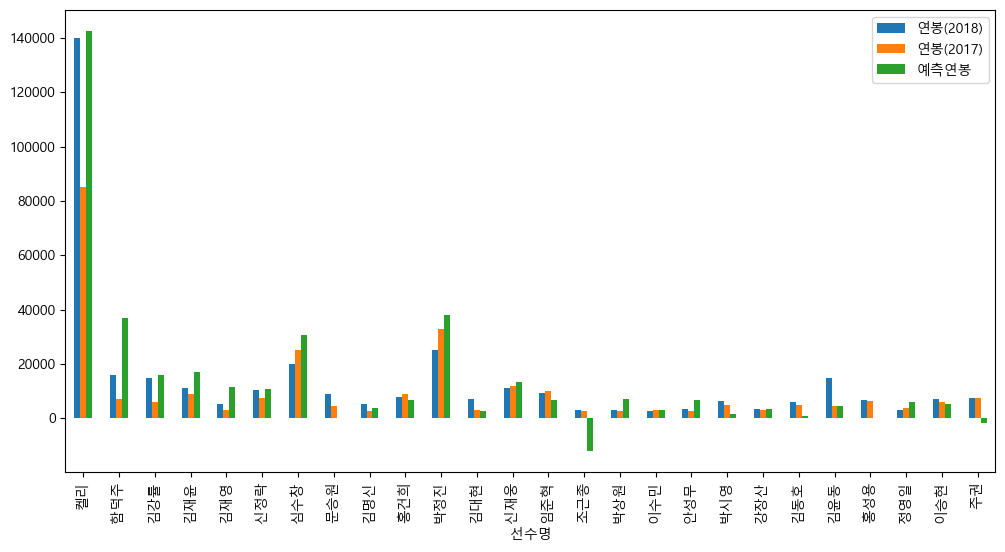

In [164]:
fig = plt.figure(figsize = (12, 6))
vis_df.plot(x = "선수명", y = ["연봉(2018)", "연봉(2017)", "예측연봉"], kind = "bar", ax = plt.gca())
plt.show()